# Seminar 5. Learning Vector Quantization II (LVQ-II)

In this notebook I go through all four tasks of the seminar:

1. **Task 1** - what is LVQ-I and LVQ-II and what is the difference
2. **Task 2** - where the LVQ-II update rule comes from and what the window parameter $\epsilon$ does
3. **Task 3** - my own implementation in NumPy, tested on 5 datasets (Iris, two synthetic 2D sets, the digits)
4. **Task 4** - comparison LVQ-I vs LVQ-II (convergence, learning rate, window) and also vs SVM, MLP and kNN

Only NumPy is used for LVQ itself. sklearn is used for loading data and for the SVM / MLP / kNN that I compare with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, make_moons, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # MLP sometimes says "not converged", not important here

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 100
colors = plt.cm.tab10.colors      # one colour for every class

## Task 1. Conceptual analysis

### Vector quantization and competitive learning

Vector quantization means: we have many data points, but we want to describe them with only a few vectors. These vectors are called **prototypes** (or codebook vectors). Every point is replaced by its nearest prototype.

In LVQ every prototype also has a **class label**. So the prototypes can be used as a classifier: a new point $x$ gets the label of its nearest prototype. The decision boundary between two classes is built from pieces of the *bisector* (the line in the middle) between neighbouring prototypes of different classes.

The learning is **competitive**: for every training point the prototypes "compete", the nearest one wins, and only the winner (or the winners) is changed. It is like k-means, but supervised, because we use the label of the training point.

### LVQ-I

For a training pair $(x, y)$ find the nearest prototype $w_c$ (the winner):

$$
w_c \leftarrow
\begin{cases}
w_c + \alpha\,(x - w_c) & \text{if } \text{class}(w_c) = y \quad \text{(pull closer)}\\
w_c - \alpha\,(x - w_c) & \text{if } \text{class}(w_c) \neq y \quad \text{(push away)}
\end{cases}
$$

Only **one** prototype moves for each training point.

### LVQ-II

Find the **two** nearest prototypes $w_i$ and $w_j$ with distances $d_i$ and $d_j$. Update only if all three conditions are true:

1. $w_i$ and $w_j$ have different classes
2. one of them has the same class as $x$ (call it $w_{good}$, the other one is $w_{bad}$)
3. $x$ is inside the window around the decision boundary:
$$\min\left(\frac{d_i}{d_j}, \frac{d_j}{d_i}\right) > s, \qquad s = \frac{1-\epsilon}{1+\epsilon}$$

Then

$$
w_{good} \leftarrow w_{good} + \alpha\,(x - w_{good}), \qquad
w_{bad} \leftarrow w_{bad} - \alpha\,(x - w_{bad})
$$

(Kohonen's original LVQ2 also demands that the *nearest* one is the wrong one. The version here, where the order does not matter, is called LVQ2.1. I use this one.)

### Main differences

| | LVQ-I | LVQ-II |
|---|---|---|
| prototypes changed per step | 1 (the winner) | 2 (the two nearest) |
| which samples cause an update | every sample | only samples near the class boundary (in the window) |
| extra parameter | none | window width $\epsilon$ |
| what it does to the boundary | moves it slowly, prototypes also drift to the class centres | moves it directly, one prototype each side |

### How LVQ-II reduces errors near the boundary

A point deep inside its class is already classified correctly. LVQ-I still moves the winner towards it, which pulls prototypes to the middle of the class (like k-means) and does not help the boundary at all. LVQ-II ignores such points.

A point near the boundary has one prototype of each class as its two nearest neighbours. LVQ-II pulls the right one closer and pushes the wrong one away **at the same time**, so the bisector between them moves across the point and the point is fixed. In LVQ-I the second prototype does not move, so the boundary moves slower.

The pictures below show (left) how the window looks for different $\epsilon$ and (right) one single update step.

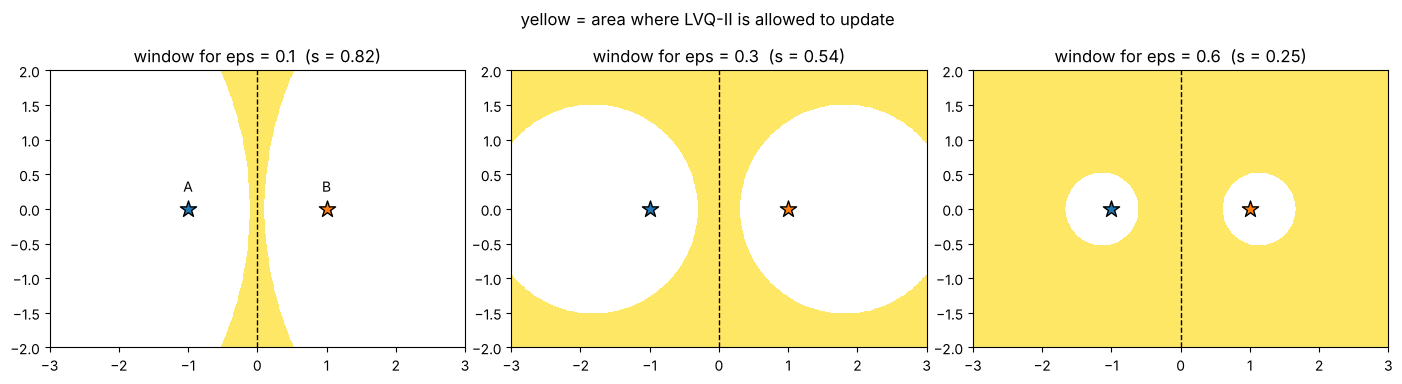

In [2]:
# two prototypes: A (class 0) on the left, B (class 1) on the right
A = np.array([-1.0, 0.0])
B = np.array([ 1.0, 0.0])

xs, ys = np.linspace(-3, 3, 500), np.linspace(-2, 2, 400)
xx, yy = np.meshgrid(xs, ys)
dA = np.sqrt((xx - A[0])**2 + (yy - A[1])**2)
dB = np.sqrt((xx - B[0])**2 + (yy - B[1])**2)
ratio = np.minimum(dA / dB, dB / dA)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, eps in zip(axs, [0.1, 0.3, 0.6]):
    s = (1 - eps) / (1 + eps)
    ax.contourf(xx, yy, (ratio > s).astype(float), levels=[0.5, 1.5], colors=["gold"], alpha=0.6)
    ax.axvline(0, color="k", ls="--", lw=1)          # bisector = decision boundary
    ax.scatter(*A, s=150, marker="*", color=colors[0], edgecolor="k", zorder=3)
    ax.scatter(*B, s=150, marker="*", color=colors[1], edgecolor="k", zorder=3)
    ax.set_title(f"window for eps = {eps}  (s = {s:.2f})")
    ax.set_aspect("equal")
axs[0].text(-1.0, 0.25, "A", ha="center"); axs[0].text(1.0, 0.25, "B", ha="center")
plt.suptitle("yellow = area where LVQ-II is allowed to update")
plt.tight_layout()
plt.show()

before: dA = 0.939, dB = 1.218 -> classified as class 0 (wrong)
window check: min ratio = 0.772 > s = 0.538 -> inside the window: True
after:  dA = 1.409, dB = 0.609 -> classified as class 1 (right)


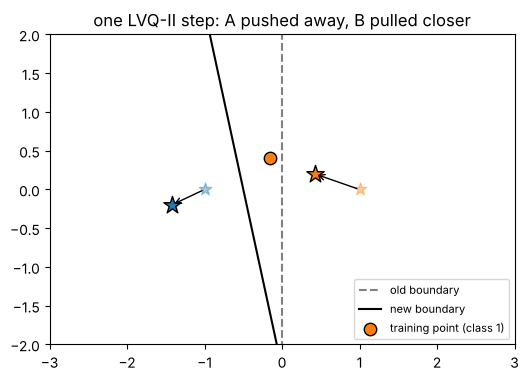

In [3]:
# one update step of LVQ-II (alpha is big here only to make the picture clear)
x = np.array([-0.15, 0.4])       # a point of class 1 (same class as B), but it is closer to A
alpha, eps = 0.5, 0.3

dA, dB = np.linalg.norm(x - A), np.linalg.norm(x - B)
s = (1 - eps) / (1 + eps)
print(f"before: dA = {dA:.3f}, dB = {dB:.3f} -> classified as class {0 if dA < dB else 1} (wrong)")
print(f"window check: min ratio = {min(dA/dB, dB/dA):.3f} > s = {s:.3f} -> inside the window: {min(dA/dB, dB/dA) > s}")

A_new = A - alpha * (x - A)      # wrong prototype is pushed away
B_new = B + alpha * (x - B)      # right prototype is pulled closer

dA2, dB2 = np.linalg.norm(x - A_new), np.linalg.norm(x - B_new)
print(f"after:  dA = {dA2:.3f}, dB = {dB2:.3f} -> classified as class {0 if dA2 < dB2 else 1} (right)")

def bisector(P, Q, ax, **kw):
    # draw the line in the middle between P and Q
    m = (P + Q) / 2
    n = Q - P
    d = np.array([-n[1], n[0]])
    d = d / np.linalg.norm(d)
    t = np.array([-3, 3])
    ax.plot(m[0] + t * d[0], m[1] + t * d[1], **kw)

fig, ax = plt.subplots(figsize=(6, 4.5))
bisector(A, B, ax, color="gray", ls="--", label="old boundary")
bisector(A_new, B_new, ax, color="k", label="new boundary")
ax.scatter(*x, s=80, color=colors[1], marker="o", edgecolor="k", label="training point (class 1)")
for P, Pn, c, nm in [(A, A_new, colors[0], "A"), (B, B_new, colors[1], "B")]:
    ax.scatter(*P, s=90, marker="*", color=c, alpha=0.4)
    ax.scatter(*Pn, s=170, marker="*", color=c, edgecolor="k")
    ax.annotate("", xy=Pn, xytext=P, arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-3, 3); ax.set_ylim(-2, 2); ax.set_aspect("equal"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("one LVQ-II step: A pushed away, B pulled closer")
plt.show()

## Task 2. Mathematical derivation

### Step 1. Competitive learning principle

The simplest competitive learning (winner-take-all) tries to make the **quantization error** small:

$$E = \frac12 \sum_n \lVert x_n - w_{c(n)} \rVert^2 ,$$

where $w_{c(n)}$ is the nearest prototype of $x_n$. For a single training point (stochastic gradient descent) only the winner $w_c$ is in the formula:

$$E(x) = \tfrac12 \lVert x - w_c \rVert^2, \qquad \frac{\partial E}{\partial w_c} = -(x - w_c)$$

$$w_c \leftarrow w_c - \alpha \frac{\partial E}{\partial w_c} = w_c + \alpha\,(x - w_c).$$

This is the unsupervised rule: the winner moves towards the point.

### Step 2. LVQ-I (add the label)

We know the class of $x$. So we multiply the cost by a sign $\sigma$: $\sigma = +1$ if the winner has the right class (we want the distance smaller), $\sigma = -1$ if the winner has the wrong class (we want the distance bigger).

$$J = \sigma \cdot \tfrac12 \lVert x - w_c \rVert^2, \qquad w_c \leftarrow w_c - \alpha \frac{\partial J}{\partial w_c} = w_c + \sigma\,\alpha\,(x - w_c)$$

This is exactly the LVQ-I rule.

### Step 3. LVQ-II

Now look at the two nearest prototypes, $w_{good}$ (class of $x$) and $w_{bad}$ (other class). The point is classified correctly when $d_{good} < d_{bad}$. Take the cost

$$f(x) = \tfrac12 \lVert x - w_{good} \rVert^2 - \tfrac12 \lVert x - w_{bad} \rVert^2 .$$

$f < 0$ means the point is correctly classified, $f > 0$ means an error. Gradients:

$$\frac{\partial f}{\partial w_{good}} = -(x - w_{good}), \qquad \frac{\partial f}{\partial w_{bad}} = +(x - w_{bad})$$

Gradient descent $w \leftarrow w - \alpha\, \partial f/\partial w$ gives

$$w_{good} \leftarrow w_{good} + \alpha\,(x - w_{good}), \qquad w_{bad} \leftarrow w_{bad} - \alpha\,(x - w_{bad}),$$

which is exactly the LVQ-II rule. So **LVQ-II is stochastic gradient descent on $f$**.

What is $f$ geometrically? Let $D = \lVert w_{bad} - w_{good} \rVert$ and let $t$ be the signed distance from $x$ to the bisector of the two prototypes (positive on the side of $w_{bad}$). Expanding the squares gives

$$f(x) = D \cdot t .$$

So $f$ is just the distance of the point from the boundary (times $D$), positive when the point is on the wrong side. Minimizing $f$ moves the bisector until the point is on the correct side. I check this numerically below.

### Step 4. Why the window is needed

$f$ has no lower bound: if we keep applying the rule, $w_{bad}$ is pushed away forever, because $-\alpha (x - w_{bad})$ gets bigger when $w_{bad}$ is far. Also, a point far away from the boundary should not change the boundary at all. So we update only if $x$ is close to the bisector, i.e. $|t|$ is small. This is the window.

The condition $\min(d_i/d_j,\, d_j/d_i) > s$ with $s = \frac{1-\epsilon}{1+\epsilon}$ can be turned into a distance. Take a point on the line between the two prototypes, at position $t$ from the midpoint. Then $d_i = D/2 + t$ and $d_j = D/2 - t$ (for $t>0$ the smaller ratio is $d_j/d_i$):

$$\frac{D/2 - t}{D/2 + t} > \frac{1-\epsilon}{1+\epsilon} \;\Longleftrightarrow\; t < \epsilon \cdot \frac{D}{2}.$$

So **between the two prototypes the window is a strip around the boundary with half-width $\epsilon \cdot D/2$**: $\epsilon$ is the width of the window as a fraction of the half-distance between the two prototypes. Away from the line that connects the prototypes the window gets wider and its edges are curved (look at the first picture of Task 1), because far away points have $d_i \approx d_j$, so the ratio is close to 1. The strip description is exact only on the line between the prototypes.

### Step 5. How $\epsilon$ influences convergence

* $\epsilon \to 0$: $s \to 1$, the strip has zero width. Almost no sample is inside, so almost no updates happen. The prototypes stay near the initial position. Stable but slow, it may not learn anything.
* $\epsilon \to 1$: $s \to 0$, the window covers everything. Every sample with two different-class neighbours causes an update, also samples far from the boundary. Because $f$ is unbounded, the wrong prototypes are pushed away again and again, they drift or oscillate and training may diverge. Bigger learning rate $\alpha$ makes it worse.
* In between there is a good range. Kohonen recommends a window of roughly 0.2 to 0.3 (relative width).
* As in all stochastic gradient methods, $\alpha$ must go to zero during training, so the prototypes settle. I use a linear decrease.

These are the theory claims. In Task 4 I test them with experiments. Here is the numerical check of the formulas above.

In [4]:
rng = np.random.default_rng(0)

# --- check 1: gradient of f really gives the LVQ-II update ---------------
def f(x, w_good, w_bad):
    return 0.5 * np.sum((x - w_good)**2) - 0.5 * np.sum((x - w_bad)**2)

x, w_good, w_bad = rng.normal(size=(3, 2))
alpha, h = 0.1, 1e-6

def num_grad(func, w):
    # simple finite differences
    g = np.zeros_like(w)
    for k in range(len(w)):
        e = np.zeros_like(w); e[k] = h
        g[k] = (func(w + e) - func(w - e)) / (2 * h)
    return g

g_good = num_grad(lambda w: f(x, w, w_bad), w_good)
g_bad  = num_grad(lambda w: f(x, w_good, w), w_bad)

print("update from gradient descent, w_good:", -alpha * g_good)
print("update from LVQ-II rule,      w_good:", alpha * (x - w_good))
print("update from gradient descent, w_bad: ", -alpha * g_bad)
print("update from LVQ-II rule,      w_bad: ", -alpha * (x - w_bad))

# --- check 2: f = D * t (distance to the bisector times D) ----------------
D = np.linalg.norm(w_bad - w_good)
normal = (w_bad - w_good) / D                    # points from good to bad
mid = (w_good + w_bad) / 2
t = np.dot(x - mid, normal)                      # signed distance to bisector
print("\nf(x) =", f(x, w_good, w_bad), "   D * t =", D * t)

# --- check 3: window half-width = eps * D / 2 -----------------------------
eps = 0.3
s = (1 - eps) / (1 + eps)
P, Q = np.array([-1.0, 0.0]), np.array([1.0, 0.0])      # D = 2
ts = np.linspace(0, 0.99, 100000)                       # points on the line, t from the middle
dP, dQ = 1 + ts, 1 - ts
inside = np.minimum(dP / dQ, dQ / dP) > s
print(f"\nwindow edge found numerically: t = {ts[~inside][0]:.4f},  eps * D/2 = {eps * 2 / 2:.4f}")

update from gradient descent, w_good: [-0.051 -0.024]
update from LVQ-II rule,      w_good: [-0.051 -0.024]
update from gradient descent, w_bad:  [-0.066  0.049]
update from LVQ-II rule,      w_bad:  [-0.066  0.049]

f(x) = -0.1800546874629866    D * t = -0.18005468746298664

window edge found numerically: t = 0.3000,  eps * D/2 = 0.3000


## Visual guide: how LVQ-I and LVQ-II work, step by step

This part explains the formulas from Task 1 and Task 2 with pictures. It has its own small step function, so it can be read without the rest of the notebook.

### 1. The two algorithms as flowcharts

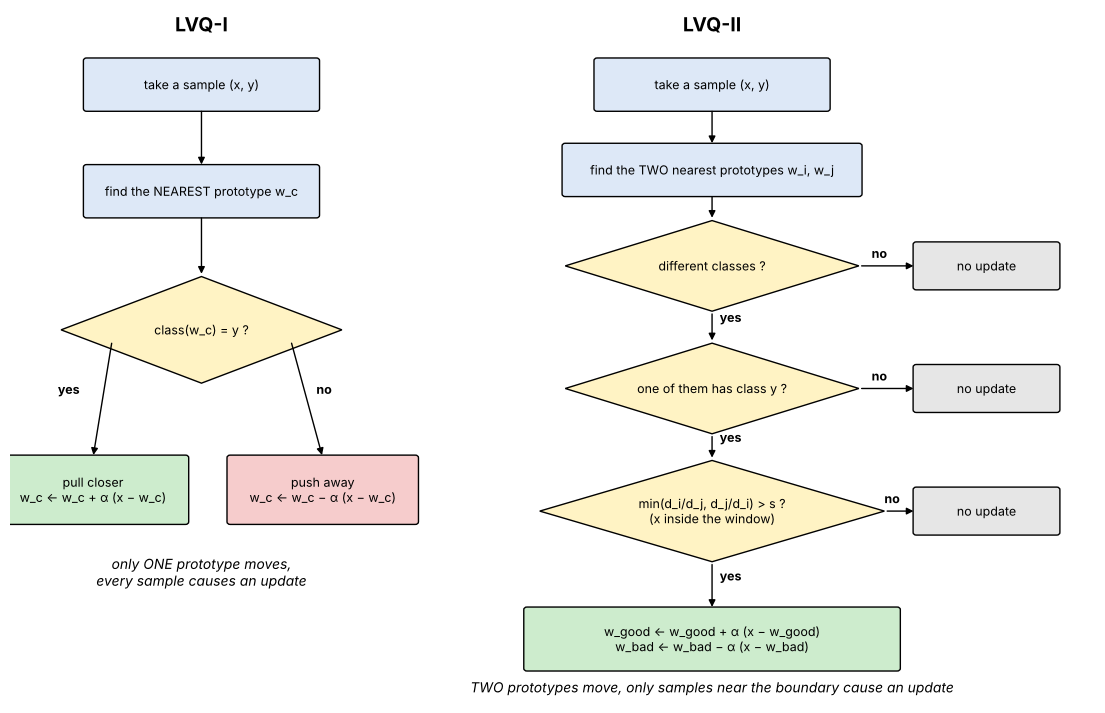

In [5]:
from matplotlib.patches import FancyBboxPatch, Polygon

def box(ax, xy, w, h, text, color="#dde8f7"):
    ax.add_patch(FancyBboxPatch((xy[0] - w / 2, xy[1] - h / 2), w, h, boxstyle="round,pad=0.05", fc=color, ec="k"))
    ax.text(xy[0], xy[1], text, ha="center", va="center", fontsize=9)

def diamond(ax, xy, w, h, text):
    x0, y0 = xy
    ax.add_patch(Polygon([(x0, y0 + h / 2), (x0 + w / 2, y0), (x0, y0 - h / 2), (x0 - w / 2, y0)], fc="#fff3c4", ec="k"))
    ax.text(x0, y0, text, ha="center", va="center", fontsize=9)

def arrow(ax, p, q, label="", dx=0.12, dy=0.1):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color="k"))
    if label:
        ax.text((p[0] + q[0]) / 2 + dx, (p[1] + q[1]) / 2 + dy, label, fontsize=9, fontweight="bold")

fig, ax = plt.subplots(figsize=(14, 9))
ax.set_xlim(0, 17); ax.set_ylim(-0.6, 12.4); ax.axis("off")
green, red, gray = "#cdeccd", "#f6cccc", "#e6e6e6"

# ---- LVQ-I ----
ax.text(3, 12.0, "LVQ-I", ha="center", fontsize=14, fontweight="bold")
box(ax, (3, 11.0), 3.6, 0.9, "take a sample (x, y)")
box(ax, (3, 9.0), 3.6, 0.9, "find the NEAREST prototype w_c")
diamond(ax, (3, 6.4), 4.4, 2.0, "class(w_c) = y ?")
box(ax, (1.3, 3.4), 2.9, 1.2, "pull closer\nw_c ← w_c + α (x − w_c)", green)
box(ax, (4.9, 3.4), 2.9, 1.2, "push away\nw_c ← w_c − α (x − w_c)", red)
arrow(ax, (3, 10.55), (3, 9.45)); arrow(ax, (3, 8.55), (3, 7.4))
arrow(ax, (1.6, 6.2), (1.3, 4.0), "yes", dx=-0.7); arrow(ax, (4.4, 6.2), (4.9, 4.0), "no", dx=0.15)
ax.text(3, 1.6, "only ONE prototype moves,\nevery sample causes an update", ha="center", fontsize=10, style="italic")

# ---- LVQ-II ----
ax.text(11, 12.0, "LVQ-II", ha="center", fontsize=14, fontweight="bold")
box(ax, (11, 11.0), 3.6, 0.9, "take a sample (x, y)")
box(ax, (11, 9.4), 4.6, 0.9, "find the TWO nearest prototypes w_i, w_j")
diamond(ax, (11, 7.6), 4.6, 1.7, "different classes ?")
diamond(ax, (11, 5.3), 4.6, 1.7, "one of them has class y ?")
diamond(ax, (11, 3.0), 5.4, 1.9, "min(d_i/d_j, d_j/d_i) > s ?\n(x inside the window)")
box(ax, (11, 0.6), 5.8, 1.1, "w_good ← w_good + α (x − w_good)\nw_bad ← w_bad − α (x − w_bad)", green)
for yy in (7.6, 5.3, 3.0):
    box(ax, (15.3, yy), 2.2, 0.8, "no update", gray)
    arrow(ax, (13.3 if yy != 3.0 else 13.7, yy), (14.2, yy), "no", dy=0.15, dx=-0.25)
arrow(ax, (11, 10.55), (11, 9.85)); arrow(ax, (11, 8.95), (11, 8.45))
arrow(ax, (11, 6.75), (11, 6.15), "yes"); arrow(ax, (11, 4.45), (11, 3.95), "yes")
arrow(ax, (11, 2.05), (11, 1.15), "yes")
ax.text(11, -0.4, "TWO prototypes move, only samples near the boundary cause an update", ha="center", fontsize=10, style="italic")
plt.show()

### 2. A small worked example with numbers

Four prototypes: $w_1=(1,1)$ and $w_3=(2,3)$ are class A, $w_2=(4,1)$ and $w_4=(4,4)$ are class B. Parameters: $\alpha = 0.1$, $\epsilon = 0.3$, so $s = (1-0.3)/(1+0.3) = 0.538$. Five training samples are shown **one at a time** (every one starts from the same prototypes), once with LVQ-I and once with LVQ-II.

In [6]:
def lvq_step(W, labels, x, y, alpha, eps, variant):
    # one training step on a COPY of W
    # returns the new W and a dictionary with information about what happened
    W = W.copy()
    d = np.sqrt(((W - x) ** 2).sum(axis=1))
    order = np.argsort(d)
    info = {"d": d, "order": order, "moved": [], "signs": []}

    if variant == "lvq1":
        c = order[0]                                    # the winner
        sign = 1 if labels[c] == y else -1
        W[c] += sign * alpha * (x - W[c])
        info.update(moved=[c], signs=[sign], why="update")
        return W, info

    i, j = order[:2]                                    # two nearest
    s = (1 - eps) / (1 + eps)
    ratio = min(d[i] / (d[j] + 1e-12), d[j] / (d[i] + 1e-12))
    info.update(pair=(i, j), ratio=ratio, s=s)
    if labels[i] == labels[j]:
        info["why"] = "same class"
    elif y != labels[i] and y != labels[j]:
        info["why"] = "none is correct"
    elif ratio <= s:
        info["why"] = "outside window"
    else:
        good, bad = (i, j) if labels[i] == y else (j, i)
        W[good] += alpha * (x - W[good])
        W[bad] -= alpha * (x - W[bad])
        info.update(moved=[good, bad], signs=[1, -1], why="update")
    return W, info

W0 = np.array([[1, 1], [4, 1], [2, 3], [4, 4]], dtype=float)
labels0 = np.array([0, 1, 0, 1])                     # 0 = class A, 1 = class B
names = ["w1", "w2", "w3", "w4"]
cls = {0: "A", 1: "B"}
samples = [("x1", (2.8, 1.2), 1), ("x2", (2.9, 1.0), 0), ("x3", (1.0, 1.1), 0),
           ("x4", (1.5, 1.0), 0), ("x5", (3.6, 0.6), 1)]
alpha_ex, eps_ex = 0.1, 0.3
print(f"s = {(1 - eps_ex) / (1 + eps_ex):.4f}")

rows = []
for nm, x, y in samples:
    x = np.array(x)
    W1, i1 = lvq_step(W0, labels0, x, y, alpha_ex, eps_ex, "lvq1")
    W2, i2 = lvq_step(W0, labels0, x, y, alpha_ex, eps_ex, "lvq2")
    c = i1["moved"][0]
    act1 = f"{names[c]} {'pulled' if i1['signs'][0] > 0 else 'pushed'}: ({W0[c,0]:.2f}, {W0[c,1]:.2f}) -> ({W1[c,0]:.2f}, {W1[c,1]:.2f})"
    p, q = i2["pair"]
    if i2["moved"]:
        g, b = i2["moved"]
        act2 = f"{names[g]} pulled, {names[b]} pushed"
    else:
        act2 = f"skip ({i2['why']})"
    rows.append({"sample": f"{nm} (class {cls[y]})", "two nearest": f"{names[p]}({cls[labels0[p]]}), {names[q]}({cls[labels0[q]]})",
                 "ratio": round(i2["ratio"], 3), "LVQ-I": act1, "LVQ-II": act2})
pd.DataFrame(rows)

s = 0.5385


,sample,two nearest,ratio,LVQ-I,LVQ-II
0,x1 (class B),"w2(B), w1(A)",0.672,"w2 pulled: (4.00, 1.00) -> (3.88, 1.02)","w2 pulled, w1 pushed"
1,x2 (class A),"w2(B), w1(A)",0.579,"w2 pushed: (4.00, 1.00) -> (4.11, 1.00)","w1 pulled, w2 pushed"
2,x3 (class A),"w1(A), w3(A)",0.047,"w1 pulled: (1.00, 1.00) -> (1.00, 1.01)",skip (same class)
3,x4 (class A),"w1(A), w3(A)",0.243,"w1 pulled: (1.00, 1.00) -> (1.05, 1.00)",skip (same class)
4,x5 (class B),"w2(B), w1(A)",0.215,"w2 pulled: (4.00, 1.00) -> (3.96, 0.96)",skip (outside window)


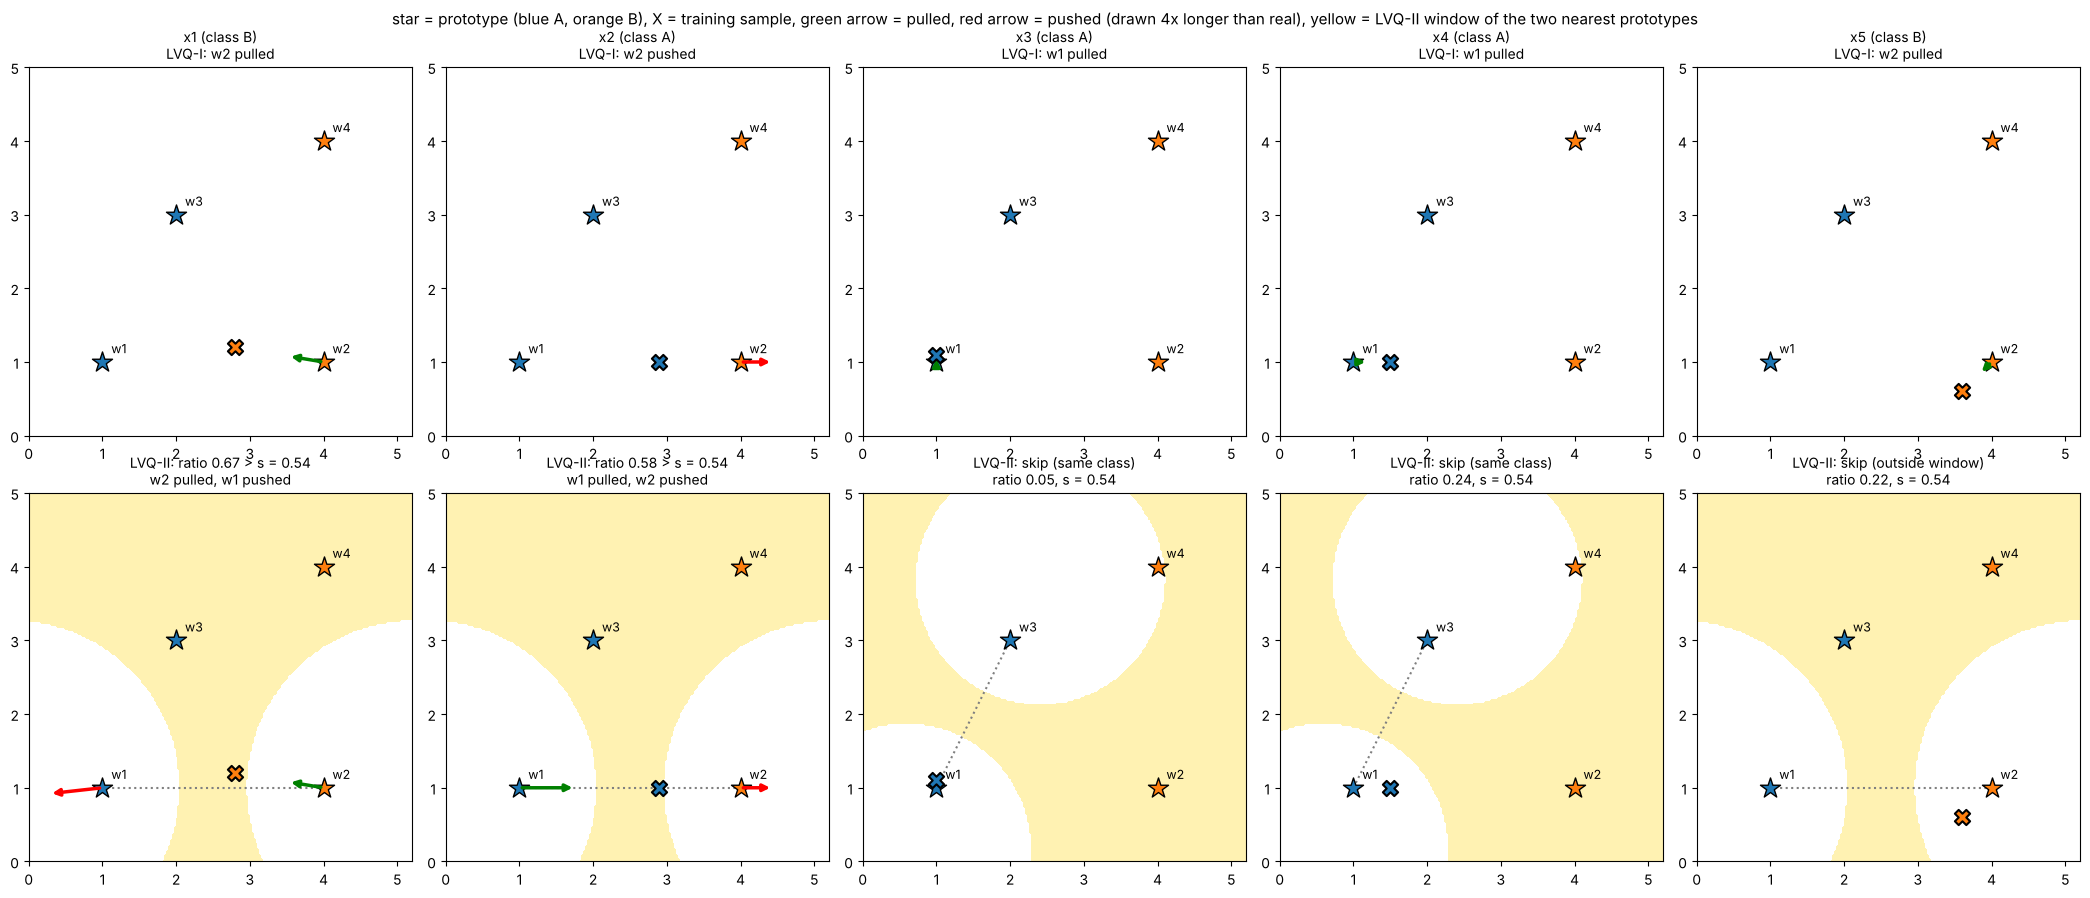

In [7]:
def draw_example(ax, x, y, variant, scale=4):
    # scale = the arrows are drawn 4 times longer than the real move, otherwise they are too small to see
    W, info = lvq_step(W0, labels0, x, y, alpha_ex, eps_ex, variant)
    if variant == "lvq2":
        i, j = info["pair"]
        gx, gy = np.meshgrid(np.linspace(0, 5.2, 200), np.linspace(0, 5, 200))
        di = np.hypot(gx - W0[i, 0], gy - W0[i, 1]); dj = np.hypot(gx - W0[j, 0], gy - W0[j, 1])
        r = np.minimum(di / (dj + 1e-12), dj / (di + 1e-12))
        ax.contourf(gx, gy, (r > info["s"]).astype(float), levels=[0.5, 1.5], colors=["gold"], alpha=0.3)
        ax.plot(W0[[i, j], 0], W0[[i, j], 1], ":", color="gray")
    for k in range(len(W0)):
        ax.scatter(*W0[k], s=230, marker="*", color=colors[labels0[k]], edgecolor="k", zorder=4)
        ax.text(W0[k, 0] + 0.12, W0[k, 1] + 0.12, names[k], fontsize=9)
    ax.scatter(*x, s=120, marker="X", color=colors[y], edgecolor="k", linewidths=1.5, zorder=6)
    for k, sg in zip(info["moved"], info["signs"]):
        tip = W0[k] + scale * (W[k] - W0[k])
        ax.annotate("", xy=tip, xytext=W0[k], zorder=5,
                    arrowprops=dict(arrowstyle="-|>", color="green" if sg > 0 else "red", lw=2.5))
    ax.set_xlim(0, 5.2); ax.set_ylim(0, 5); ax.set_aspect("equal")
    return info

fig, axs = plt.subplots(2, 5, figsize=(21, 9))
for col, (nm, x, y) in enumerate(samples):
    x = np.array(x)
    i1 = draw_example(axs[0, col], x, y, "lvq1")
    c = i1["moved"][0]
    axs[0, col].set_title(f"{nm} (class {cls[y]})\nLVQ-I: {names[c]} {'pulled' if i1['signs'][0] > 0 else 'pushed'}", fontsize=10)
    i2 = draw_example(axs[1, col], x, y, "lvq2")
    if i2["moved"]:
        t2 = f"LVQ-II: ratio {i2['ratio']:.2f} > s = {i2['s']:.2f}\n{names[i2['moved'][0]]} pulled, {names[i2['moved'][1]]} pushed"
    else:
        t2 = f"LVQ-II: skip ({i2['why']})\nratio {i2['ratio']:.2f}, s = {i2['s']:.2f}"
    axs[1, col].set_title(t2, fontsize=10)
fig.suptitle("star = prototype (blue A, orange B), X = training sample, green arrow = pulled, red arrow = pushed (drawn 4x longer than real), "
             "yellow = LVQ-II window of the two nearest prototypes", fontsize=11)
plt.tight_layout()
plt.show()

What to see in the picture:

* **Top row (LVQ-I):** in every column exactly one prototype moves. The winner is pulled if its class is right and pushed if it is wrong (x2).
* **Bottom row (LVQ-II):** x1 and x2 are inside the yellow window, so **two** prototypes move, one is pulled and the other is pushed. For x3 and x4 the two nearest prototypes have the same class, for x5 the sample is outside of the window, so nothing happens.
* Only x1 and x2 are near the boundary between A and B, and only they move the boundary in LVQ-II.

### 3. The window as a picture: the ratio along the line between two prototypes

Prototype A is at $-1$, prototype B is at $+1$ ($D = 2$), and $t$ is the position of the sample on the line between them. The curve is $\min(d_A/d_B,\, d_B/d_A)$. It is 1 in the middle (on the boundary) and goes to 0 when the sample comes to a prototype. The window is the part where the curve is above $s$. The horizontal lines are $s$ for three values of $\epsilon$, and the dots show that the window edge is exactly at $t = \pm\epsilon D/2$.

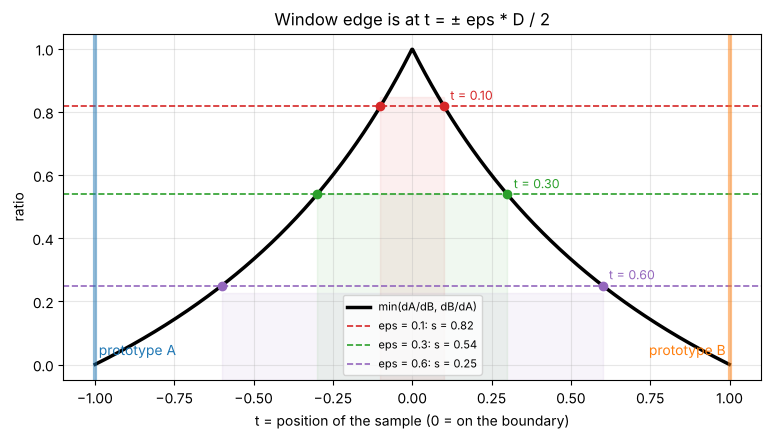

In [8]:
D = 2.0
t = np.linspace(-D / 2 + 1e-3, D / 2 - 1e-3, 1000)
dA, dB = D / 2 + t, D / 2 - t
ratio = np.minimum(dA / dB, dB / dA)

plt.figure(figsize=(9, 4.5))
plt.plot(t, ratio, "k", lw=2.5, label="min(dA/dB, dB/dA)")
for eps, c in zip([0.1, 0.3, 0.6], ["tab:red", "tab:green", "tab:purple"]):
    s = (1 - eps) / (1 + eps)
    plt.axhline(s, color=c, ls="--", lw=1.2, label=f"eps = {eps}: s = {s:.2f}")
    edge = eps * D / 2
    plt.scatter([-edge, edge], [s, s], color=c, zorder=5)
    plt.axvspan(-edge, edge, ymin=0, ymax=s, color=c, alpha=0.07)
    plt.text(edge + 0.02, s + 0.02, f"t = {edge:.2f}", color=c, fontsize=9)
plt.axvline(-1, color="tab:blue", lw=3, alpha=.5); plt.axvline(1, color="tab:orange", lw=3, alpha=.5)
plt.text(-1, 0.03, " prototype A", color="tab:blue"); plt.text(1, 0.03, "prototype B ", color="tab:orange", ha="right")
plt.xlabel("t = position of the sample (0 = on the boundary)")
plt.ylabel("ratio")
plt.title("Window edge is at t = ± eps * D / 2")
plt.legend(fontsize=8, loc="lower center"); plt.grid(alpha=.3)
plt.show()

### 4. How far does the boundary move in one LVQ-II step?

Let $g$ be the good prototype, $b$ the bad one, $m = (g+b)/2$ the middle (a point of the boundary), and $D = \lVert b - g \rVert$. After one step $g' = g + \alpha(x-g)$ and $b' = b - \alpha(x-b)$. Adding them:

$$g' + b' = g + b + \alpha\,(b - g) \quad\Longrightarrow\quad m' = m + \frac{\alpha}{2}\,(b - g)$$

So **the boundary moves by $\alpha D/2$ towards the bad prototype, and this does not depend on where $x$ is.** The position of $x$ only decides if the step is allowed (the window). If a misclassified sample is at distance $t$ from the boundary, one step fixes it when $t < \alpha D / 2$, otherwise more steps are needed.

The picture shows this on a line with $g = -2$, $b = +2$ ($D = 4$) and $\alpha = 0.3$, so one step moves the boundary by $0.6$. The sample is blue (class of $g$) but it lies on the orange side.

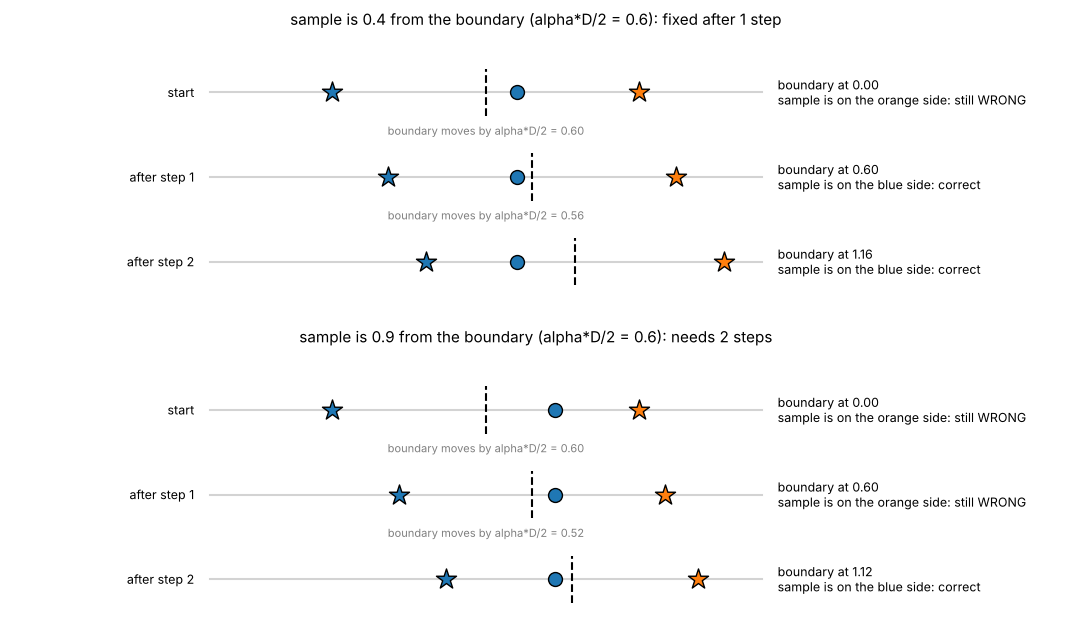

In [9]:
def line_picture(ax, y_pos, g, b, x, label):
    ax.plot([-3.6, 3.6], [y_pos, y_pos], color="lightgray", zorder=1)
    ax.scatter(g, y_pos, s=230, marker="*", color=colors[0], edgecolor="k", zorder=3)
    ax.scatter(b, y_pos, s=230, marker="*", color=colors[1], edgecolor="k", zorder=3)
    m = (g + b) / 2
    ax.plot([m, m], [y_pos - 0.28, y_pos + 0.28], "k--", lw=1.5, zorder=2)
    ax.scatter(x, y_pos, s=100, marker="o", color=colors[0], edgecolor="k", zorder=4)   # sample of the class of g
    side = "blue side: correct" if x < m else "orange side: still WRONG"
    ax.text(-3.8, y_pos, label, ha="right", va="center", fontsize=9)
    ax.text(3.8, y_pos, f"boundary at {m:.2f}\nsample is on the {side}", ha="left", va="center", fontsize=9)

alpha_l, g0, b0 = 0.3, -2.0, 2.0
fig, axs = plt.subplots(2, 1, figsize=(11, 6.5))
for ax, t_x in zip(axs, [0.4, 0.9]):
    g, b, xs_ = g0, b0, t_x
    need = []
    for step in range(3):
        line_picture(ax, 2 - step, g, b, xs_, "start" if step == 0 else f"after step {step}")
        D_now = b - g
        g, b = g + alpha_l * (xs_ - g), b - alpha_l * (xs_ - b)
        if step < 2:
            ax.text(0, 1.5 - step, f"boundary moves by alpha*D/2 = {alpha_l * D_now / 2:.2f}", ha="center", fontsize=8, color="gray")
    ax.set_xlim(-6.2, 7.5); ax.set_ylim(-0.6, 2.7); ax.axis("off")
    ax.set_title(f"sample is {t_x} from the boundary (alpha*D/2 = {alpha_l * 4 / 2:.1f}): "
                 + ("fixed after 1 step" if t_x < alpha_l * 4 / 2 else "needs 2 steps"), fontsize=11)
plt.tight_layout()
plt.show()

The window half-width is $\epsilon D/2$ and the boundary step is $\alpha D/2$. If $\alpha > \epsilon$, even the farthest sample of the window is fixed in one step and the boundary jumps over the whole window, which can make training unstable. This is only a rough estimate, but it explains why $\alpha$ should be small compared to $\epsilon$.

### 5. Which samples change the prototypes?

Two classes with some overlap. First the prototypes are trained 10 epochs with LVQ-I to get a normal start. Then one more epoch is done with LVQ-I and with LVQ-II from the same prototypes ($\alpha = 0.03$, $\epsilon = 0.3$). Big dots with a black edge = this sample moved at least one prototype. Small grey dots = it did not.

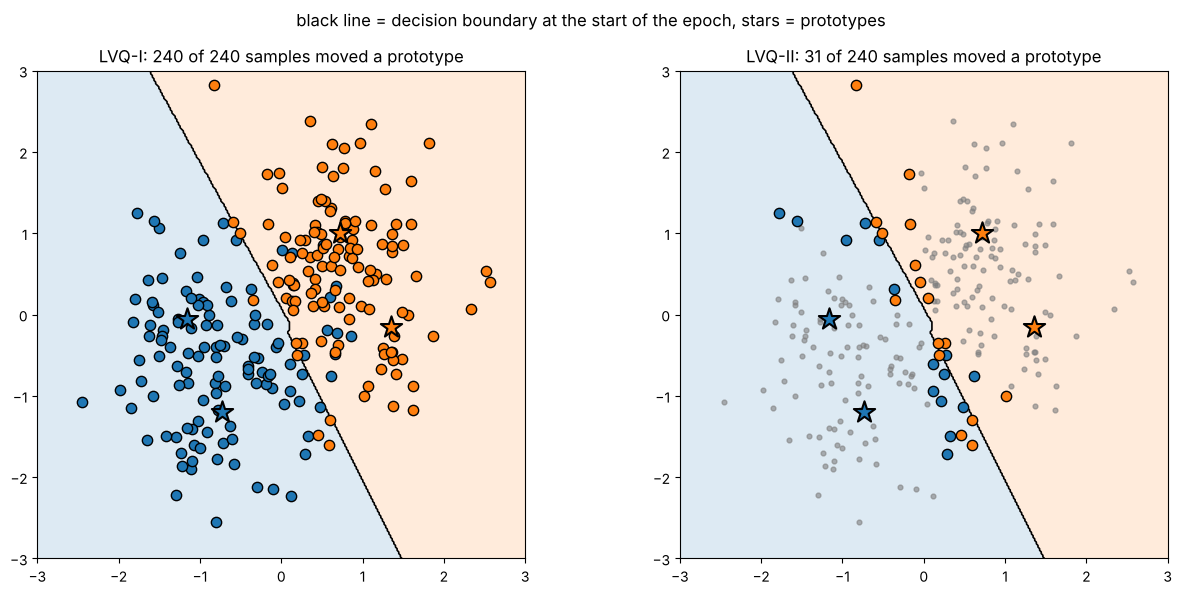

In [10]:
Xd, yd = make_blobs(n_samples=240, centers=[[0, 0], [2.2, 1.2]], cluster_std=1.0, random_state=4)
Xd = StandardScaler().fit_transform(Xd)

rng_d = np.random.default_rng(0)
idx = np.concatenate([rng_d.choice(np.where(yd == k)[0], 2, replace=False) for k in [0, 1]])
Wd, ld = Xd[idx].copy(), yd[idx].copy()
for ep in range(10):                                  # normal LVQ-I start
    for n in rng_d.permutation(len(Xd)):
        Wd, _ = lvq_step(Wd, ld, Xd[n], yd[n], 0.05, 0.3, "lvq1")

def one_epoch(W, variant, alpha=0.03):
    flags = np.zeros(len(Xd), dtype=bool)
    for n in np.random.default_rng(1).permutation(len(Xd)):
        W, info = lvq_step(W, ld, Xd[n], yd[n], alpha, 0.3, variant)
        flags[n] = len(info["moved"]) > 0
    return W, flags

gx, gy = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
grid_d = ((np.c_[gx.ravel(), gy.ravel()][:, None, :] - Wd[None, :, :]) ** 2).sum(axis=2)
Zd = ld[grid_d.argmin(axis=1)].reshape(gx.shape)

fig, axs = plt.subplots(1, 2, figsize=(13, 6))
for ax, variant, nm in zip(axs, ["lvq1", "lvq2"], ["LVQ-I", "LVQ-II"]):
    W_after, flags = one_epoch(Wd, variant)
    ax.contourf(gx, gy, Zd, levels=[-.5, .5, 1.5], colors=colors[:2], alpha=.15)
    ax.contour(gx, gy, Zd, levels=[.5], colors="k", linewidths=1.2)
    ax.scatter(*Xd[~flags].T, s=12, color="gray", alpha=.6)
    for k in range(2):
        sel = flags & (yd == k)
        ax.scatter(*Xd[sel].T, s=55, color=colors[k], edgecolor="k", zorder=3)
    for k in range(len(Wd)):
        ax.scatter(*Wd[k], s=260, marker="*", color=colors[ld[k]], edgecolor="k", linewidths=1.5, zorder=5)
    ax.set_title(f"{nm}: {flags.sum()} of {len(Xd)} samples moved a prototype")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.suptitle("black line = decision boundary at the start of the epoch, stars = prototypes")
plt.tight_layout()
plt.show()

LVQ-I uses all samples. LVQ-II uses only the samples that are close to the black boundary line, the others are ignored. This is the whole idea of the window, and it is the reason why LVQ-II makes much fewer updates in the convergence plots of Task 4.

## Task 3. Implementation

### The LVQ class

* `variant="lvq1"` updates only the winner
* `variant="lvq2"` updates the two nearest prototypes inside the window

The prototypes are started as random training points of every class. The learning rate goes down linearly from `alpha` to 0 over the epochs. After each epoch I save the prototype positions and the accuracy, so I can draw them later.

In [11]:
class LVQ:
    def __init__(self, per_class=2, alpha=0.05, eps=0.3, epochs=30, variant="lvq2", seed=0):
        self.per_class = per_class     # prototypes for each class
        self.alpha = alpha             # starting learning rate
        self.eps = eps                 # window parameter (only for lvq2)
        self.epochs = epochs
        self.variant = variant
        self.seed = seed

    def start_protos(self, X, y, rng):
        # initial prototypes = random points from every class
        W, labels = [], []
        for k in np.unique(y):
            ids = rng.choice(np.where(y == k)[0], self.per_class, replace=False)
            W.append(X[ids])
            labels += [k] * self.per_class
        return np.vstack(W).astype(float), np.array(labels)

    def predict(self, X):
        # nearest prototype
        d = ((X[:, None, :] - self.W[None, :, :]) ** 2).sum(axis=2)
        return self.labels[d.argmin(axis=1)]

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

    def update(self, x, label, alpha):
        # one training step, returns True if some prototype was moved
        d = np.sqrt(((self.W - x) ** 2).sum(axis=1))

        if self.variant == "lvq1":
            c = d.argmin()                              # the winner
            sign = 1 if self.labels[c] == label else -1
            self.W[c] += sign * alpha * (x - self.W[c])
            return True

        # ---- LVQ-II ----
        i, j = np.argsort(d)[:2]                        # two nearest prototypes
        if self.labels[i] == self.labels[j]:
            return False                                # same class -> nothing to do
        if label != self.labels[i] and label != self.labels[j]:
            return False                                # none of them is right
        s = (1 - self.eps) / (1 + self.eps)
        if min(d[i] / (d[j] + 1e-12), d[j] / (d[i] + 1e-12)) <= s:   # 1e-12: avoid division by 0
            return False                                # outside of the window
        good, bad = (i, j) if self.labels[i] == label else (j, i)
        self.W[good] += alpha * (x - self.W[good])      # pull the right one
        self.W[bad]  -= alpha * (x - self.W[bad])       # push the wrong one
        return True

    def fit(self, X, y, Xtest=None, ytest=None, W0=None, labels0=None):
        rng = np.random.default_rng(self.seed)
        if W0 is None:
            self.W, self.labels = self.start_protos(X, y, rng)
        else:
            self.W, self.labels = W0.copy(), labels0.copy()

        self.history = [self.W.copy()]                  # prototypes after every epoch
        self.train_acc = [self.score(X, y)]
        self.test_acc = [self.score(Xtest, ytest)] if Xtest is not None else []
        self.n_updates = []

        for ep in range(self.epochs):
            alpha = self.alpha * (1 - ep / self.epochs)
            count = 0
            for n in rng.permutation(len(X)):           # shuffle every epoch
                count += self.update(X[n], y[n], alpha)
            self.history.append(self.W.copy())
            self.n_updates.append(count)
            self.train_acc.append(self.score(X, y))
            if Xtest is not None:
                self.test_acc.append(self.score(Xtest, ytest))
        return self

In [12]:
# sanity check: the class and the small step function from the visual guide do the same thing
rng_c = np.random.default_rng(5)
same = True
for _ in range(300):
    W = rng_c.normal(size=(6, 2)); labs = np.array([0, 0, 1, 1, 2, 2])
    x, y = rng_c.normal(size=2), rng_c.integers(0, 3)
    for variant in ["lvq1", "lvq2"]:
        m = LVQ(variant=variant, alpha=0.1, eps=0.3)
        m.W, m.labels = W.copy(), labs
        m.update(x, y, 0.1)
        W_ref, _ = lvq_step(W, labs, x, y, 0.1, 0.3, variant)
        same &= np.allclose(m.W, W_ref)
print("LVQ class and lvq_step agree on 600 random steps:", same)

LVQ class and lvq_step agree on 600 random steps: True


### Datasets

I use five datasets, so we can see how LVQ behaves in different situations:

| name | classes | features | comment |
|---|---|---|---|
| `iris2` | 3 | 2 (petal length, width) | easy, can be drawn in 2D |
| `iris4` | 3 | 4 | the full Iris, versicolor and virginica overlap a bit |
| `moons` | 2 | 2 | two half moons with noise, not linearly separable |
| `blobs` | 3 | 2 | three clusters that overlap a lot, so there is a real boundary problem |
| `digits` | 10 | 64 | handwritten digits 8x8, a "real" dataset |

Every dataset is split 70% train / 30% test (stratified).

In [13]:
# synthetic datasets are made once with a fixed seed
Xm, ym = make_moons(n_samples=400, noise=0.25, random_state=1)
Xb, yb = make_blobs(n_samples=450, centers=[[0, 0], [2.5, 1], [1, 3]], cluster_std=1.1, random_state=2)
iris, digits = load_iris(), load_digits()

# per_class = how many prototypes for every class (for this dataset)
datasets = {
    "iris2":  dict(X=iris.data[:, 2:4], y=iris.target, per_class=2),
    "iris4":  dict(X=iris.data,         y=iris.target, per_class=2),
    "moons":  dict(X=Xm,                y=ym,          per_class=3),
    "blobs":  dict(X=Xb,                y=yb,          per_class=2),
    "digits": dict(X=digits.data / 16,  y=digits.target, per_class=3),   # pixels 0..16 -> 0..1
}

def get_data(name, seed=0):
    X, y = datasets[name]["X"], datasets[name]["y"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
    if name != "digits":                  # standardize (fit only on the train part)
        sc = StandardScaler().fit(Xtr)
        Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    return Xtr, Xte, ytr, yte

for name in datasets:
    Xtr, Xte, ytr, yte = get_data(name)
    print(f"{name:7s} train {Xtr.shape}  test {Xte.shape}  classes {len(np.unique(ytr))}")

iris2   train (105, 2)  test (45, 2)  classes 3
iris4   train (105, 4)  test (45, 4)  classes 3
moons   train (280, 2)  test (120, 2)  classes 2
blobs   train (315, 2)  test (135, 2)  classes 3
digits  train (1257, 64)  test (540, 64)  classes 10


### Plot functions (initial prototypes, paths over the epochs, final decision regions)

I train LVQ-I and LVQ-II from the **same** starting prototypes, so the difference comes only from the algorithm.

In [14]:
def draw_regions(ax, model, X, y, title):
    # coloured background = what the model predicts, black line = decision boundary
    K = len(np.unique(y))
    pts = np.vstack([X, model.W])          # the plot must also cover the prototypes
    xx, yy = np.meshgrid(np.linspace(pts[:, 0].min() - .7, pts[:, 0].max() + .7, 300),
                         np.linspace(pts[:, 1].min() - .7, pts[:, 1].max() + .7, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(-.5, K), colors=colors[:K], alpha=.2)
    ax.contour(xx, yy, Z, levels=np.arange(.5, K - 1), colors="k", linewidths=1)
    for k in range(K):
        ax.scatter(*X[y == k].T, s=12, color=colors[k], alpha=.7)
        P = model.W[model.labels == k]
        ax.scatter(*P.T, s=170, marker="*", color=colors[k], edgecolor="k", lw=1.2, zorder=5)
    ax.set_title(title)

def show_run(name, m1, m2, X, y):
    K = len(np.unique(y))
    fig, axs = plt.subplots(2, 3, figsize=(15, 9))
    for row, (m, nm) in enumerate([(m1, "LVQ-I"), (m2, "LVQ-II")]):
        # 1) initial prototypes
        ax = axs[row, 0]
        for k in range(K):
            ax.scatter(*X[y == k].T, s=12, color=colors[k], alpha=.6)
            ax.scatter(*m.history[0][m.labels == k].T, s=170, marker="*", color=colors[k], edgecolor="k", lw=1.2)
        ax.set_title(f"{nm}: initial prototypes")
        # 2) path of every prototype during the epochs
        ax = axs[row, 1]
        H = np.array(m.history)                     # shape (epochs+1, prototypes, 2)
        for k in range(K):
            ax.scatter(*X[y == k].T, s=10, color=colors[k], alpha=.2)
        for p in range(H.shape[1]):
            c = colors[m.labels[p]]
            ax.plot(H[:, p, 0], H[:, p, 1], "-o", color=c, ms=3, lw=1.2)
            ax.scatter(*H[0, p], s=70, facecolor="white", edgecolor=c, lw=1.8, zorder=4)     # start
            ax.scatter(*H[-1, p], s=170, marker="*", color=c, edgecolor="k", lw=1.2, zorder=5)  # end
        ax.set_title(f"{nm}: path after each epoch (o start, * end)")
        # 3) final regions
        draw_regions(axs[row, 2], m, X, y, f"{nm}: final regions, train acc {m.train_acc[-1]:.3f}")
    plt.suptitle(name, fontsize=14)
    plt.tight_layout()
    plt.show()

def show_epochs(m, X, y, epochs, title):
    # decision regions after some chosen epochs
    fig, axs = plt.subplots(1, len(epochs), figsize=(3.6 * len(epochs), 3.6))
    tmp = LVQ()
    tmp.labels = m.labels
    for ax, e in zip(axs, epochs):
        tmp.W = m.history[e]
        draw_regions(ax, tmp, X, y, f"epoch {e}")
        ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

def train_both(name, seed=3, alpha=0.05, eps=0.3, epochs=30):
    # same split, same start prototypes for both
    Xtr, Xte, ytr, yte = get_data(name)
    pc = datasets[name]["per_class"]
    start = LVQ(per_class=pc)
    W0, l0 = start.start_protos(Xtr, ytr, np.random.default_rng(seed))
    m1 = LVQ(pc, alpha, eps, epochs, "lvq1").fit(Xtr, ytr, Xte, yte, W0, l0)
    m2 = LVQ(pc, alpha, eps, epochs, "lvq2").fit(Xtr, ytr, Xte, yte, W0, l0)
    return m1, m2, Xtr, Xte, ytr, yte

#### Dataset 1: Iris (2 features)

LVQ-I : train 0.952  test 0.978
LVQ-II: train 0.952  test 1.000


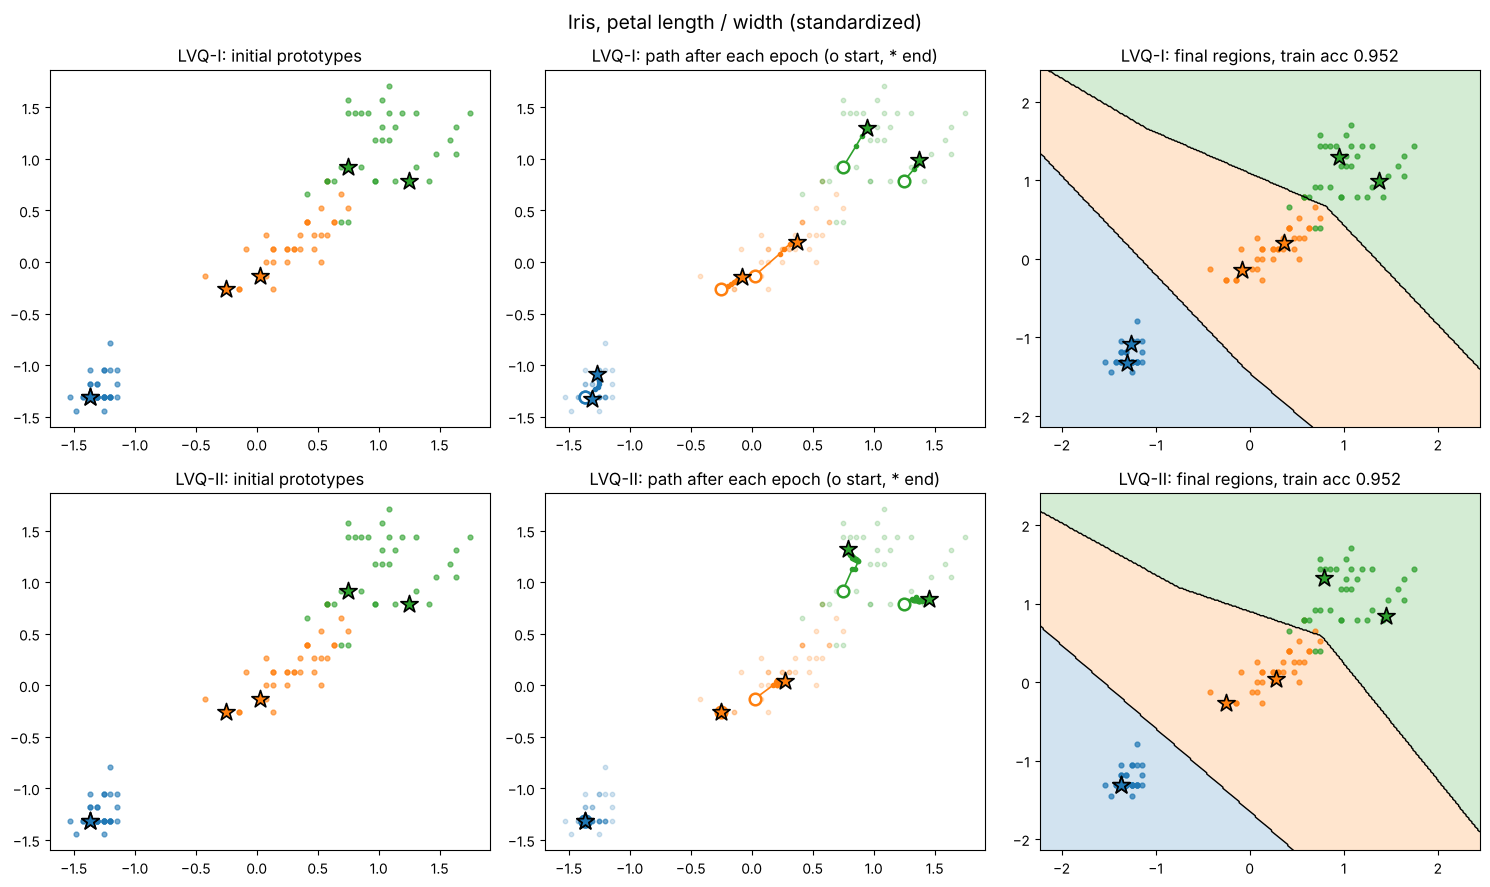

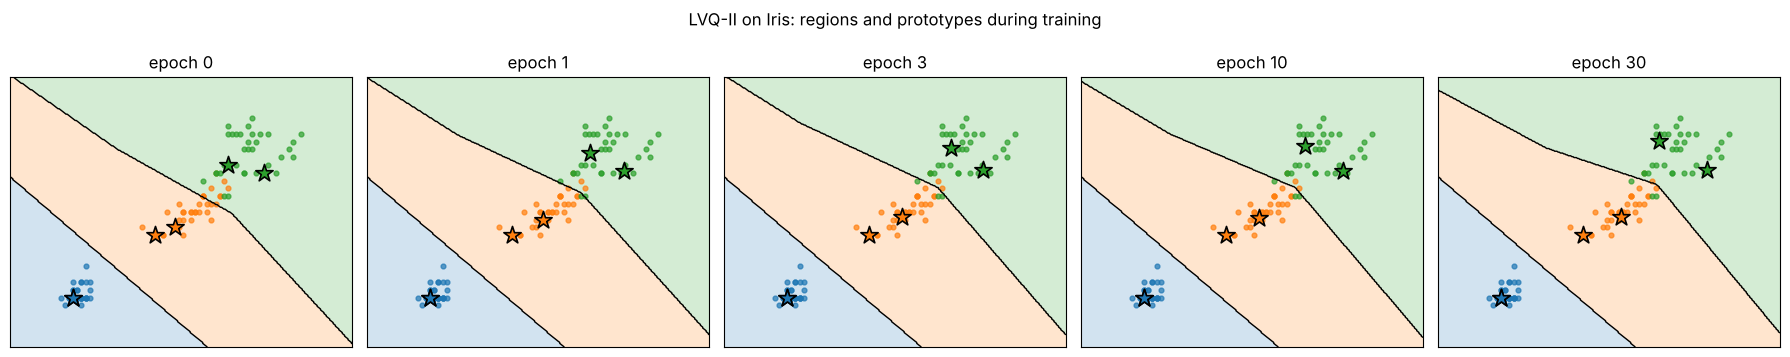

In [15]:
m1, m2, Xtr, Xte, ytr, yte = train_both("iris2")
print(f"LVQ-I : train {m1.train_acc[-1]:.3f}  test {m1.test_acc[-1]:.3f}")
print(f"LVQ-II: train {m2.train_acc[-1]:.3f}  test {m2.test_acc[-1]:.3f}")
show_run("Iris, petal length / width (standardized)", m1, m2, Xtr, ytr)
show_epochs(m2, Xtr, ytr, [0, 1, 3, 10, 30], "LVQ-II on Iris: regions and prototypes during training")

#### Dataset 2: Moons (2 classes, not linearly separable)

LVQ-I : train 0.936  test 0.908
LVQ-II: train 0.900  test 0.900


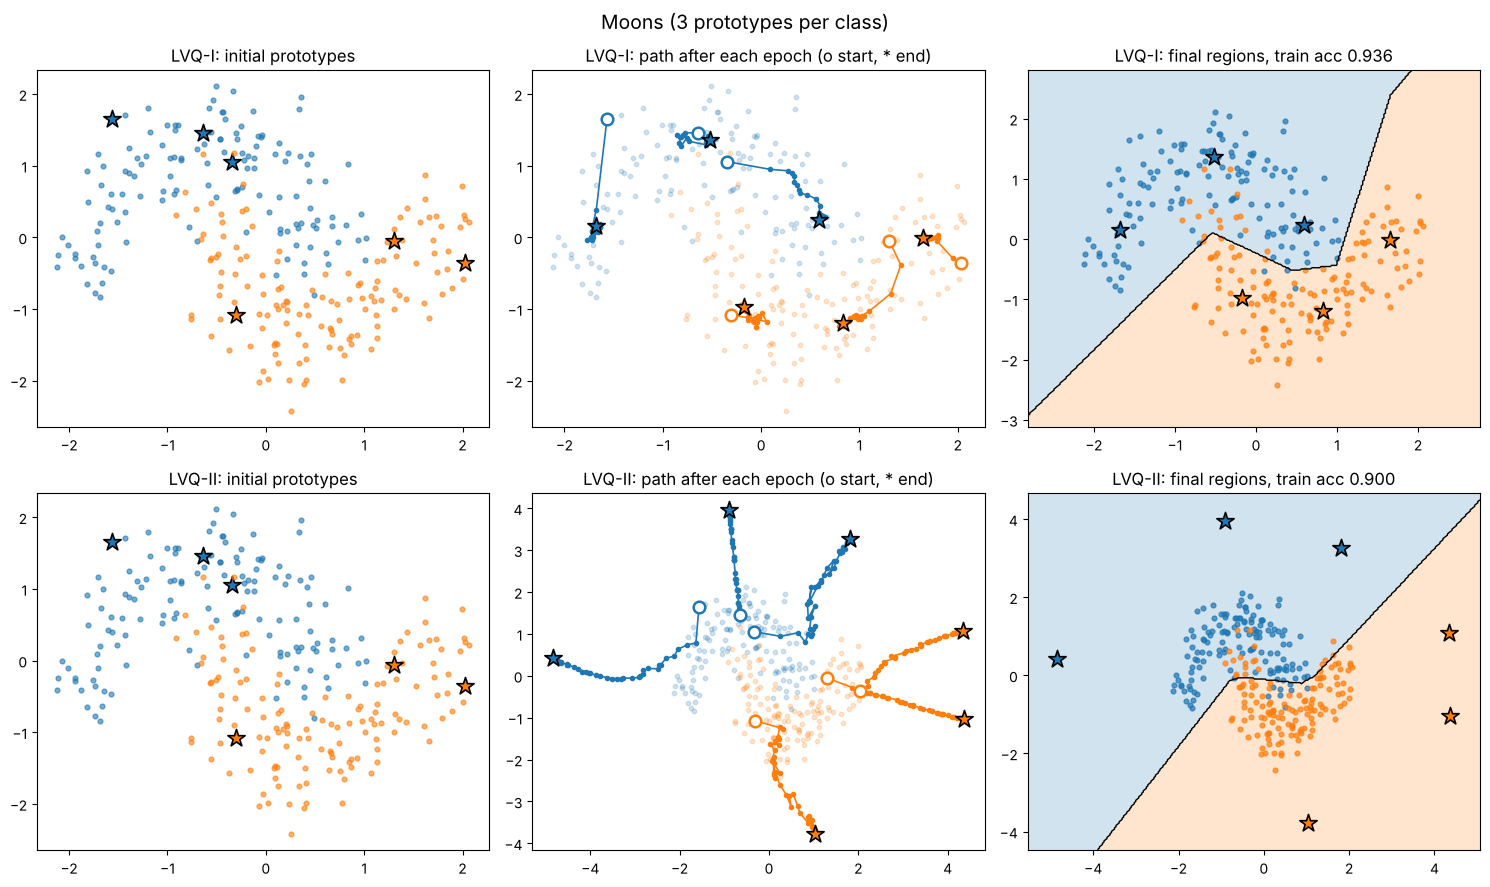

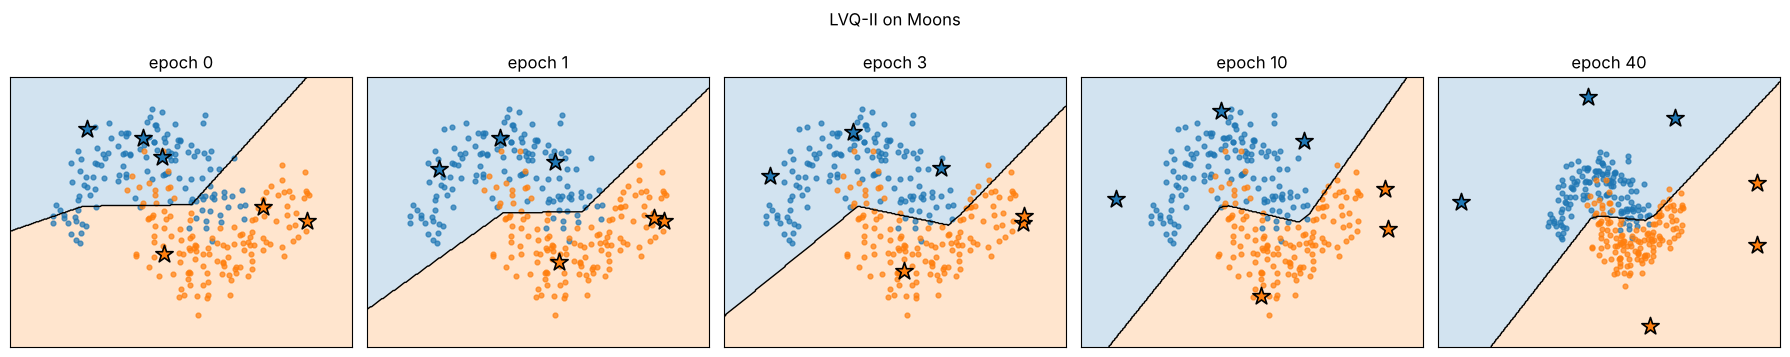

In [16]:
m1, m2, Xtr, Xte, ytr, yte = train_both("moons", epochs=40)
print(f"LVQ-I : train {m1.train_acc[-1]:.3f}  test {m1.test_acc[-1]:.3f}")
print(f"LVQ-II: train {m2.train_acc[-1]:.3f}  test {m2.test_acc[-1]:.3f}")
show_run("Moons (3 prototypes per class)", m1, m2, Xtr, ytr)
show_epochs(m2, Xtr, ytr, [0, 1, 3, 10, 40], "LVQ-II on Moons")

**Look at the LVQ-II path here.** The prototypes do not stay near the data, they run away to the outside (the axes are much bigger than for LVQ-I). This is the problem from Step 4 of Task 2: the cost $f$ has no lower bound, so the wrong prototype is pushed away again and again. The window should stop this, but with random starting points on a noisy dataset many samples are inside the window all the time. The classifier still works, because only the position of the boundary between the prototypes matters, but the prototypes are no longer "typical examples" of their class. In 4.4 I test the usual way to avoid this (LVQ-I first, LVQ-II only for fine tuning).

#### Dataset 3: Blobs (3 overlapping clusters)

LVQ-I : train 0.848  test 0.830
LVQ-II: train 0.857  test 0.830


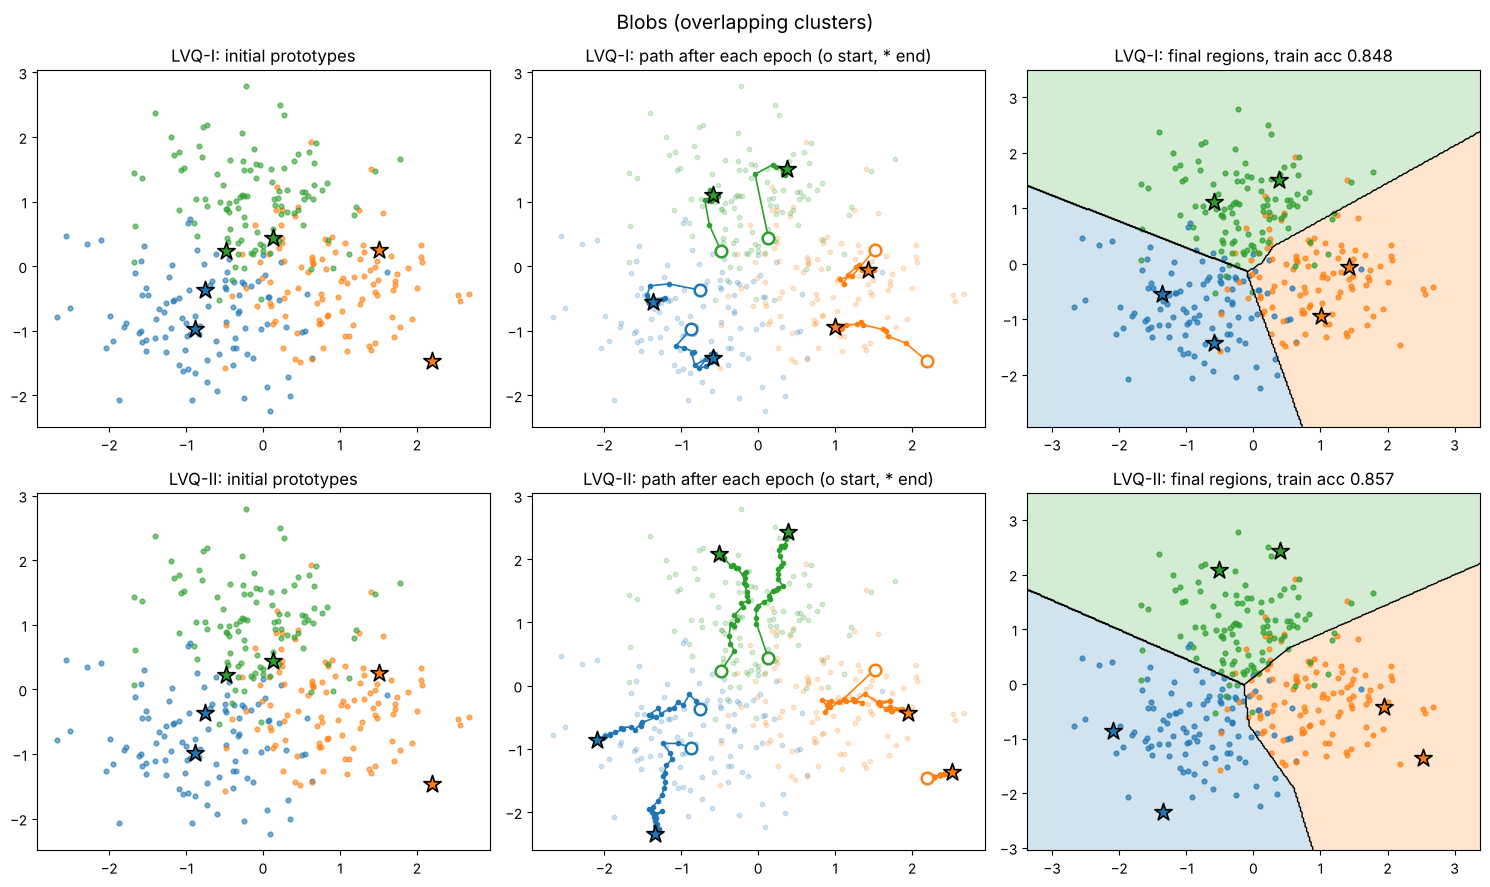

In [17]:
m1, m2, Xtr, Xte, ytr, yte = train_both("blobs")
print(f"LVQ-I : train {m1.train_acc[-1]:.3f}  test {m1.test_acc[-1]:.3f}")
print(f"LVQ-II: train {m2.train_acc[-1]:.3f}  test {m2.test_acc[-1]:.3f}")
show_run("Blobs (overlapping clusters)", m1, m2, Xtr, ytr)

#### Dataset 4: Iris with all 4 features

Four features cannot be drawn, so here I only look at the accuracy during the epochs.

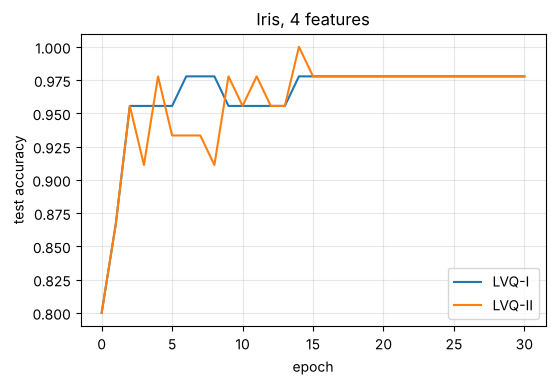

LVQ-I : train 0.952  test 0.978
LVQ-II: train 0.962  test 0.978


In [18]:
m1, m2, Xtr, Xte, ytr, yte = train_both("iris4")
plt.figure(figsize=(6, 3.8))
plt.plot(m1.test_acc, label="LVQ-I"); plt.plot(m2.test_acc, label="LVQ-II")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.title("Iris, 4 features"); plt.legend(); plt.grid(alpha=.3)
plt.show()
print(f"LVQ-I : train {m1.train_acc[-1]:.3f}  test {m1.test_acc[-1]:.3f}")
print(f"LVQ-II: train {m2.train_acc[-1]:.3f}  test {m2.test_acc[-1]:.3f}")

#### Dataset 5: Handwritten digits (10 classes, 64 features)

For the digits the prototypes are 64-dimensional vectors, so they can be shown as 8x8 images. This is a nice thing about LVQ: the prototypes can be "read" by a human. Rows: LVQ-II prototypes, 3 per digit.

LVQ-I : train 0.955  test 0.943
LVQ-II: train 0.986  test 0.969


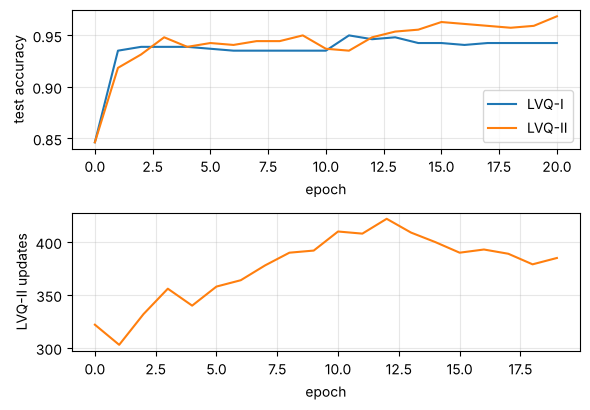

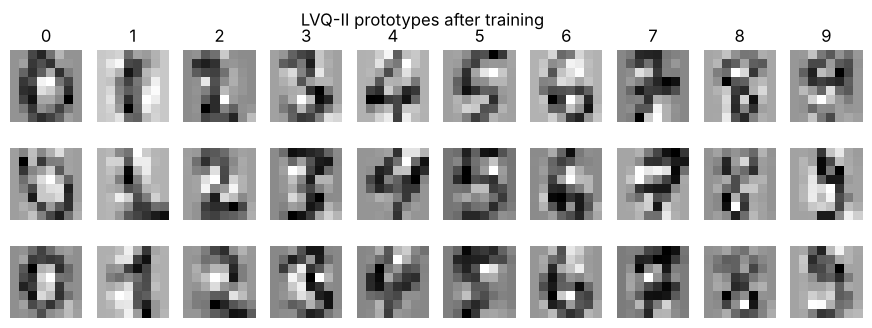

In [19]:
m1, m2, Xtr, Xte, ytr, yte = train_both("digits", alpha=0.05, eps=0.3, epochs=20)
print(f"LVQ-I : train {m1.train_acc[-1]:.3f}  test {m1.test_acc[-1]:.3f}")
print(f"LVQ-II: train {m2.train_acc[-1]:.3f}  test {m2.test_acc[-1]:.3f}")

fig, axs = plt.subplots(2, 1, figsize=(6, 4.2))
axs[0].plot(m1.test_acc, label="LVQ-I"); axs[0].plot(m2.test_acc, label="LVQ-II")
axs[0].set_xlabel("epoch"); axs[0].set_ylabel("test accuracy"); axs[0].legend(); axs[0].grid(alpha=.3)
axs[1].plot(m2.n_updates, color="C1"); axs[1].set_xlabel("epoch"); axs[1].set_ylabel("LVQ-II updates"); axs[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

# prototypes as images: columns = digits 0..9, rows = the 3 prototypes
fig, axs = plt.subplots(3, 10, figsize=(11, 3.6))
for k in range(10):
    P = m2.W[m2.labels == k]
    for r in range(3):
        axs[r, k].imshow(P[r].reshape(8, 8), cmap="gray_r"); axs[r, k].axis("off")
    axs[0, k].set_title(str(k))
plt.suptitle("LVQ-II prototypes after training")
plt.show()

## Task 4. Evaluation

### 4.1 Convergence: LVQ-I vs LVQ-II

For every dataset I repeat the experiment with several different random splits and different start prototypes (same start for both algorithms) and average the curves. Settings: $\alpha_0 = 0.05$, $\epsilon = 0.3$.

"Epochs to converge" is counted for every single run as the first epoch where the train accuracy is within 1 percentage point of its final value, and the table shows the average of this number over the runs.

In [20]:
def compare(name, seeds, alpha=0.05, eps=0.3, epochs=30):
    # returns arrays [seed, epoch] for train / test / updates, for both variants
    out = {"lvq1": ([], [], []), "lvq2": ([], [], [])}
    pc = datasets[name]["per_class"]
    for s in seeds:
        Xtr, Xte, ytr, yte = get_data(name, seed=s)
        W0, l0 = LVQ(per_class=pc).start_protos(Xtr, ytr, np.random.default_rng(s))
        for v in out:
            m = LVQ(pc, alpha, eps, epochs, v, seed=s).fit(Xtr, ytr, Xte, yte, W0, l0)
            out[v][0].append(m.train_acc); out[v][1].append(m.test_acc); out[v][2].append(m.n_updates)
    return {v: [np.array(a) for a in out[v]] for v in out}

def epochs_to_converge(curve):
    return int(np.argmax(curve >= curve[-1] - 0.01))

seeds_for = {"iris2": range(20), "iris4": range(20), "moons": range(10), "blobs": range(10), "digits": range(4)}
epochs_for = {"iris2": 30, "iris4": 30, "moons": 30, "blobs": 30, "digits": 20}

results = {}
for name in datasets:
    results[name] = compare(name, seeds_for[name], epochs=epochs_for[name])
    print("done", name)

done iris2


done iris4


done moons


done blobs


done digits


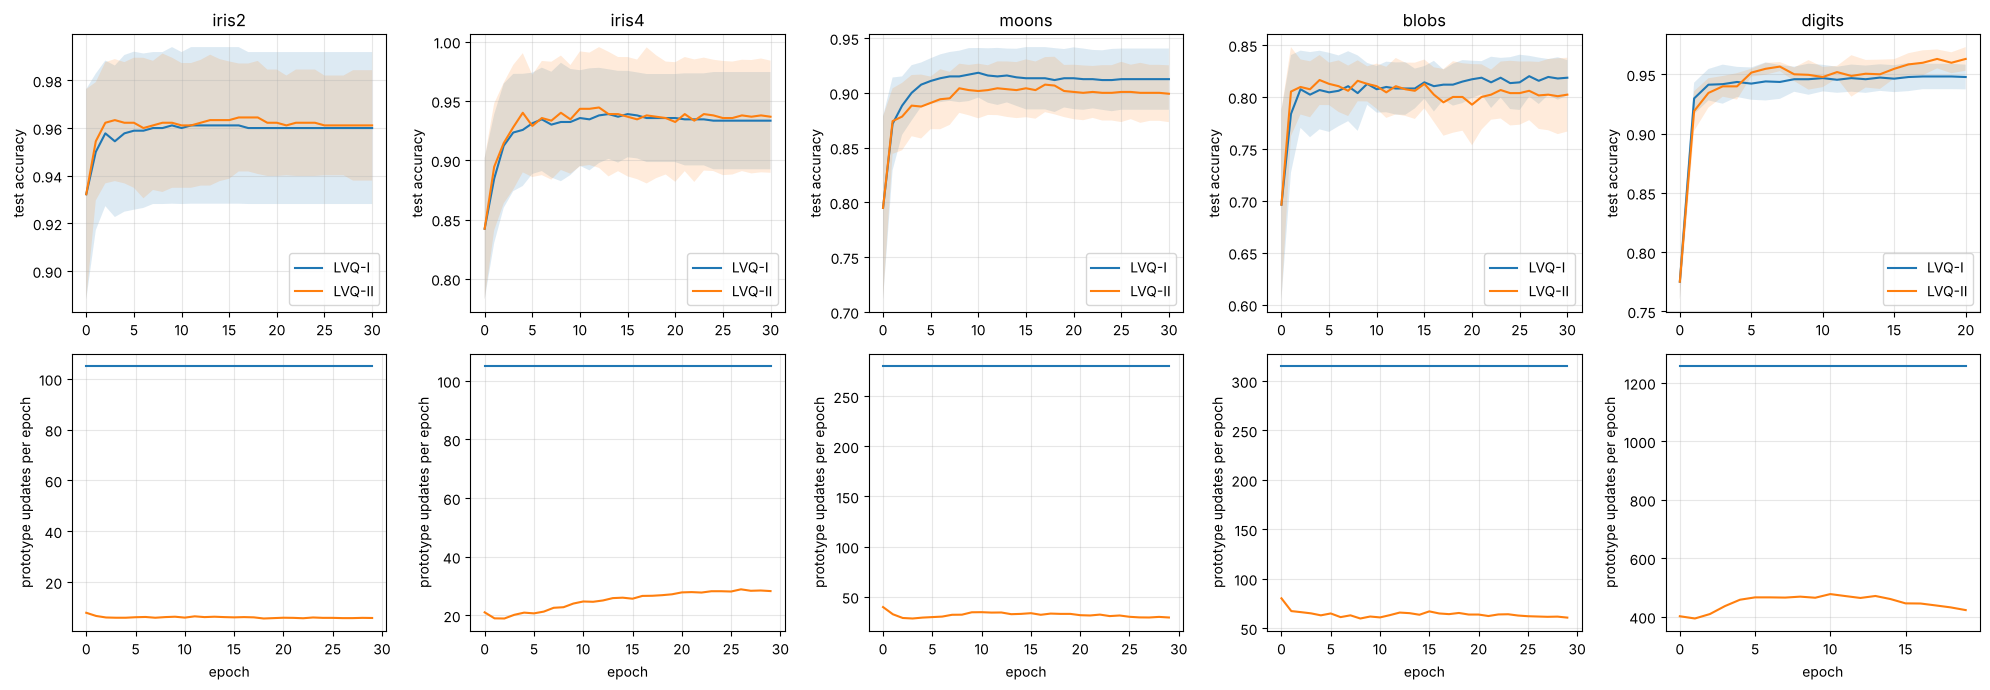

,dataset,model,train acc,test acc,epochs to converge,updates per epoch (first → last)
0,iris2,LVQ-I,0.959 ± 0.011,0.960 ± 0.032,0.9,105 → 105
1,iris2,LVQ-II,0.962 ± 0.012,0.961 ± 0.023,1.6,8 → 6
2,iris4,LVQ-I,0.953 ± 0.025,0.933 ± 0.041,3.6,105 → 105
3,iris4,LVQ-II,0.965 ± 0.027,0.937 ± 0.047,3.6,21 → 28
4,moons,LVQ-I,0.919 ± 0.012,0.912 ± 0.028,3.7,280 → 280
5,moons,LVQ-II,0.901 ± 0.026,0.899 ± 0.026,4.0,40 → 29
6,blobs,LVQ-I,0.835 ± 0.035,0.819 ± 0.017,4.4,315 → 315
7,blobs,LVQ-II,0.836 ± 0.024,0.802 ± 0.036,2.4,80 → 61
8,digits,LVQ-I,0.966 ± 0.006,0.948 ± 0.010,3.2,1257 → 1257
9,digits,LVQ-II,0.984 ± 0.004,0.963 ± 0.010,6.5,402 → 423


In [21]:
fig, axs = plt.subplots(2, 5, figsize=(20, 7))
rows = []
for col, name in enumerate(datasets):
    for v, label in [("lvq1", "LVQ-I"), ("lvq2", "LVQ-II")]:
        tr, te, up = results[name][v]
        mu, sd = te.mean(0), te.std(0)
        axs[0, col].plot(mu, label=label)
        axs[0, col].fill_between(range(len(mu)), mu - sd, mu + sd, alpha=.15)
        axs[1, col].plot(up.mean(0), label=label)
        rows.append({"dataset": name, "model": label,
                     "train acc": f"{tr[:, -1].mean():.3f} ± {tr[:, -1].std():.3f}",
                     "test acc": f"{te[:, -1].mean():.3f} ± {te[:, -1].std():.3f}",
                     "epochs to converge": np.mean([epochs_to_converge(c) for c in tr]).round(1),
                     "updates per epoch (first → last)": f"{up.mean(0)[0]:.0f} → {up.mean(0)[-1]:.0f}"})
    axs[0, col].set_title(name); axs[0, col].set_ylabel("test accuracy"); axs[0, col].grid(alpha=.3); axs[0, col].legend()
    axs[1, col].set_xlabel("epoch"); axs[1, col].set_ylabel("prototype updates per epoch"); axs[1, col].grid(alpha=.3)
plt.tight_layout()
plt.show()

table_conv = pd.DataFrame(rows)
table_conv

In [22]:
# is the difference LVQ-II minus LVQ-I bigger than the noise?
for name in datasets:
    d = results[name]["lvq2"][1][:, -1] - results[name]["lvq1"][1][:, -1]
    print(f"{name:7s} test acc LVQ-II minus LVQ-I: mean {d.mean():+.4f}, std {d.std():.4f}, runs {len(d)}")

iris2   test acc LVQ-II minus LVQ-I: mean +0.0011, std 0.0216, runs 20
iris4   test acc LVQ-II minus LVQ-I: mean +0.0033, std 0.0488, runs 20
moons   test acc LVQ-II minus LVQ-I: mean -0.0133, std 0.0259, runs 10
blobs   test acc LVQ-II minus LVQ-I: mean -0.0163, std 0.0229, runs 10
digits  test acc LVQ-II minus LVQ-I: mean +0.0153, std 0.0038, runs 4


### 4.2 Sensitivity to the learning rate $\alpha_0$ and the window $\epsilon$

I make a grid of $\alpha_0$ and $\epsilon$ and measure the final test accuracy (average over 8 runs). It is done for `iris4` and `moons`. The line for LVQ-I does not depend on $\epsilon$.

In [23]:
alphas = [0.001, 0.005, 0.01, 0.03, 0.05, 0.1, 0.3]
epss = [0.05, 0.1, 0.2, 0.3, 0.5, 0.8]

def sensitivity(name, seeds=range(8), epochs=20):
    pc = datasets[name]["per_class"]
    data = []
    for s in seeds:
        Xtr, Xte, ytr, yte = get_data(name, seed=s)
        W0, l0 = LVQ(per_class=pc).start_protos(Xtr, ytr, np.random.default_rng(s))
        data.append((Xtr, Xte, ytr, yte, W0, l0, s))

    def final_test(variant, a, e):
        accs = [LVQ(pc, a, e, epochs, variant, seed=s).fit(Xtr, ytr, W0=W0, labels0=l0).score(Xte, yte)
                for Xtr, Xte, ytr, yte, W0, l0, s in data]
        return np.mean(accs)

    line1 = [final_test("lvq1", a, 0) for a in alphas]
    grid = np.array([[final_test("lvq2", a, e) for a in alphas] for e in epss])
    return line1, grid

sens = {}
for name in ["iris4", "moons"]:
    sens[name] = sensitivity(name)
    print("done", name)

done iris4


done moons


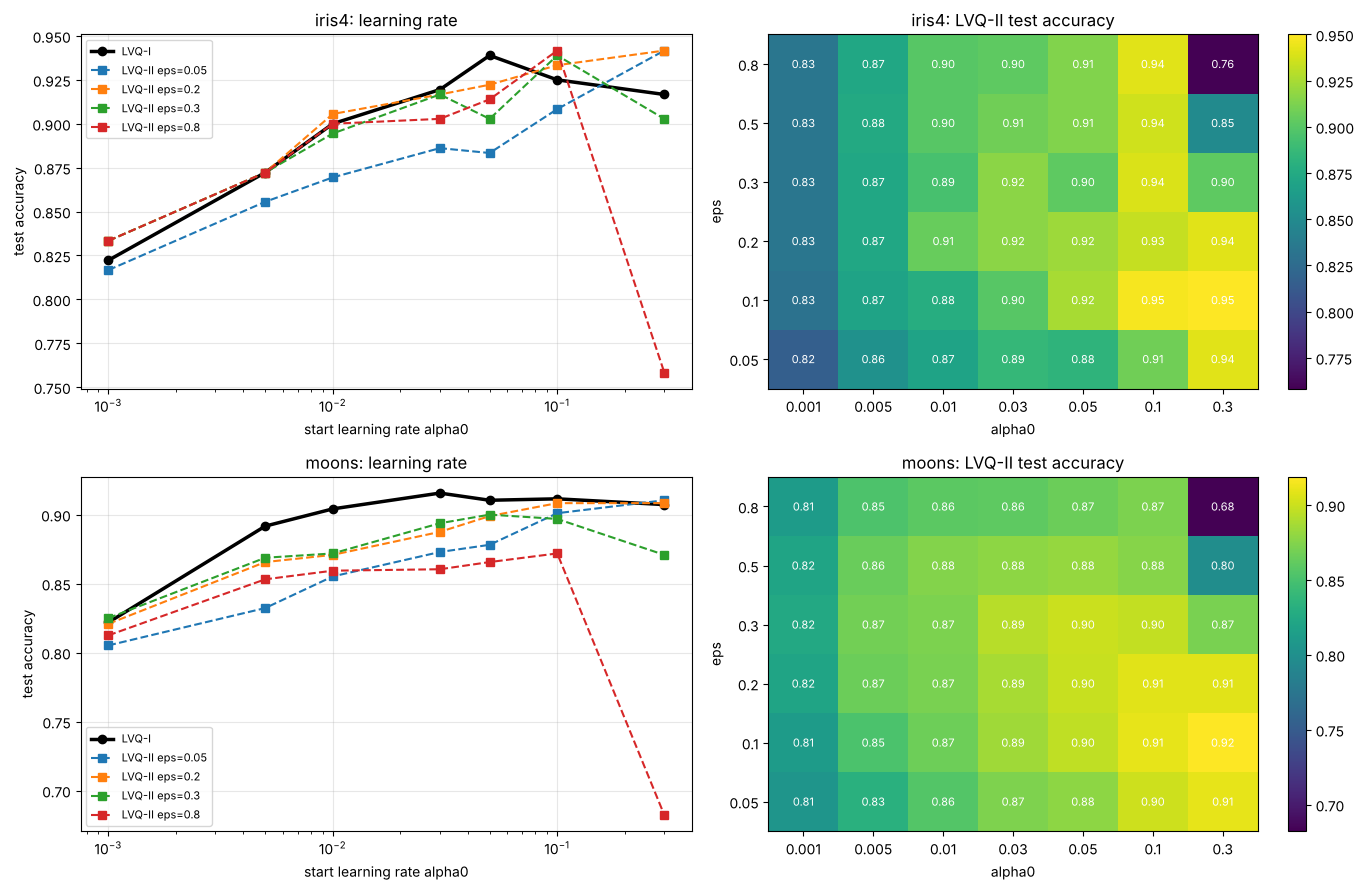

In [24]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
for r, name in enumerate(["iris4", "moons"]):
    line1, grid = sens[name]
    ax = axs[r, 0]
    ax.semilogx(alphas, line1, "o-", lw=2.5, color="k", label="LVQ-I")
    for i in [0, 2, 3, 5]:
        ax.semilogx(alphas, grid[i], "s--", label=f"LVQ-II eps={epss[i]}")
    ax.set_xlabel("start learning rate alpha0"); ax.set_ylabel("test accuracy")
    ax.set_title(f"{name}: learning rate"); ax.grid(alpha=.3); ax.legend(fontsize=8)

    ax = axs[r, 1]
    im = ax.imshow(grid, origin="lower", aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(alphas))); ax.set_xticklabels(alphas)
    ax.set_yticks(range(len(epss))); ax.set_yticklabels(epss)
    for i in range(len(epss)):
        for j in range(len(alphas)):
            ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
    ax.set_xlabel("alpha0"); ax.set_ylabel("eps"); ax.set_title(f"{name}: LVQ-II test accuracy")
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [25]:
# the same numbers as tables
for name in ["iris4", "moons"]:
    line1, grid = sens[name]
    t = pd.DataFrame(grid.T, index=[f"alpha0={a}" for a in alphas], columns=[f"eps={e}" for e in epss])
    t.insert(0, "LVQ-I", line1)
    print(name)
    display(t.round(3))

iris4


,LVQ-I,eps=0.05,eps=0.1,eps=0.2,eps=0.3,eps=0.5,eps=0.8
alpha0=0.001,0.822,0.817,0.831,0.833,0.833,0.833,0.833
alpha0=0.005,0.872,0.856,0.869,0.872,0.872,0.875,0.872
alpha0=0.01,0.900,0.869,0.878,0.906,0.894,0.900,0.900
alpha0=0.03,0.919,0.886,0.900,0.917,0.917,0.908,0.903
alpha0=0.05,0.939,0.883,0.925,0.922,0.903,0.914,0.914
alpha0=0.1,0.925,0.908,0.947,0.933,0.939,0.936,0.942
alpha0=0.3,0.917,0.942,0.950,0.942,0.903,0.850,0.758


moons


,LVQ-I,eps=0.05,eps=0.1,eps=0.2,eps=0.3,eps=0.5,eps=0.8
alpha0=0.001,0.822,0.805,0.812,0.821,0.825,0.821,0.812
alpha0=0.005,0.892,0.832,0.852,0.866,0.869,0.865,0.853
alpha0=0.01,0.904,0.855,0.867,0.871,0.872,0.875,0.859
alpha0=0.03,0.916,0.873,0.885,0.888,0.894,0.878,0.860
alpha0=0.05,0.910,0.878,0.896,0.899,0.900,0.881,0.866
alpha0=0.1,0.911,0.901,0.910,0.908,0.897,0.876,0.872
alpha0=0.3,0.907,0.910,0.919,0.908,0.871,0.798,0.682


### 4.3 Comparison with SVM, MLP and kNN

Same splits as before. SVM is the default RBF SVC, MLP has one hidden layer with 20 neurons, kNN uses k = 5. The last column shows how many numbers the model has to store for prediction (for LVQ: prototypes x features, for kNN: the whole training set).

In [26]:
def other_models(seed):
    return {
        "SVM (RBF)": SVC(),
        "MLP (20 hidden)": MLPClassifier((20,), max_iter=1000, random_state=seed),
        "kNN (k=5)": KNeighborsClassifier(5),
    }

rows = []
for name in datasets:
    pc = datasets[name]["per_class"]
    accs = {}
    for s in seeds_for[name]:
        Xtr, Xte, ytr, yte = get_data(name, seed=s)
        accs.setdefault("LVQ-I", []).append(results[name]["lvq1"][1][list(seeds_for[name]).index(s)][-1])
        accs.setdefault("LVQ-II", []).append(results[name]["lvq2"][1][list(seeds_for[name]).index(s)][-1])
        for nm, model in other_models(s).items():
            accs.setdefault(nm, []).append(model.fit(Xtr, ytr).score(Xte, yte))
    n_feat = datasets[name]["X"].shape[1]
    n_class = len(np.unique(datasets[name]["y"]))
    n_train = len(get_data(name)[2])
    stored = {"LVQ-I": pc * n_class * n_feat, "LVQ-II": pc * n_class * n_feat, "kNN (k=5)": n_train * n_feat}
    for nm, v in accs.items():
        rows.append({"dataset": name, "classifier": nm, "test acc": f"{np.mean(v):.3f} ± {np.std(v):.3f}",
                     "stored numbers": stored.get(nm, "-")})

table_other = pd.DataFrame(rows)
table_other.pivot(index="classifier", columns="dataset", values="test acc")[list(datasets)]

dataset,iris2,iris4,moons,blobs,digits
classifier,,,,,
LVQ-I,0.960 ± 0.032,0.933 ± 0.041,0.912 ± 0.028,0.819 ± 0.017,0.948 ± 0.010
LVQ-II,0.961 ± 0.023,0.937 ± 0.047,0.899 ± 0.026,0.802 ± 0.036,0.963 ± 0.010
MLP (20 hidden),0.960 ± 0.033,0.963 ± 0.032,0.908 ± 0.028,0.823 ± 0.020,0.969 ± 0.006
SVM (RBF),0.962 ± 0.029,0.958 ± 0.036,0.922 ± 0.017,0.821 ± 0.019,0.985 ± 0.002
kNN (k=5),0.968 ± 0.030,0.951 ± 0.033,0.926 ± 0.019,0.804 ± 0.030,0.982 ± 0.003


In [27]:
table_other[table_other["classifier"].isin(["LVQ-I", "LVQ-II", "kNN (k=5)"])][["dataset", "classifier", "stored numbers"]] \
    .pivot(index="classifier", columns="dataset", values="stored numbers")[list(datasets)]

dataset,iris2,iris4,moons,blobs,digits
classifier,,,,,
LVQ-I,12,24,12,12,1920
LVQ-II,12,24,12,12,1920
kNN (k=5),210,420,560,630,80448


### 4.4 LVQ-II as fine tuning after LVQ-I

Kohonen recommends not to start with LVQ-II. First train with LVQ-I so the prototypes are already in the right places, then run LVQ-II a few epochs with a small learning rate to correct the boundary. Here: 2/3 of the epochs LVQ-I ($\alpha_0 = 0.05$), then 1/3 of the epochs LVQ-II ($\alpha_0 = 0.01$, $\epsilon = 0.3$). The total number of epochs is the same as in 4.1.

In [28]:
def hybrid(name, seeds):
    pc = datasets[name]["per_class"]
    total = epochs_for[name]
    e1 = total * 2 // 3
    e2 = total - e1
    res = {"LVQ-I": [], "LVQ-II": [], "LVQ-I then LVQ-II": []}
    for s in seeds:
        Xtr, Xte, ytr, yte = get_data(name, seed=s)
        W0, l0 = LVQ(per_class=pc).start_protos(Xtr, ytr, np.random.default_rng(s))
        a = LVQ(pc, 0.05, 0.3, total, "lvq1", seed=s).fit(Xtr, ytr, W0=W0, labels0=l0)
        b = LVQ(pc, 0.05, 0.3, total, "lvq2", seed=s).fit(Xtr, ytr, W0=W0, labels0=l0)
        c1 = LVQ(pc, 0.05, 0.3, e1, "lvq1", seed=s).fit(Xtr, ytr, W0=W0, labels0=l0)
        c2 = LVQ(pc, 0.01, 0.3, e2, "lvq2", seed=s).fit(Xtr, ytr, W0=c1.W, labels0=c1.labels)
        res["LVQ-I"].append(a.score(Xte, yte))
        res["LVQ-II"].append(b.score(Xte, yte))
        res["LVQ-I then LVQ-II"].append(c2.score(Xte, yte))
    return res

rows = []
for name in datasets:
    r = hybrid(name, seeds_for[name])
    for k, v in r.items():
        rows.append({"dataset": name, "training": k, "test acc": f"{np.mean(v):.3f} ± {np.std(v):.3f}"})
    print("done", name)

pd.DataFrame(rows).pivot(index="training", columns="dataset", values="test acc")[list(datasets)]

done iris2


done iris4


done moons


done blobs


done digits


dataset,iris2,iris4,moons,blobs,digits
training,,,,,
LVQ-I,0.960 ± 0.032,0.933 ± 0.041,0.912 ± 0.028,0.819 ± 0.017,0.948 ± 0.010
LVQ-I then LVQ-II,0.962 ± 0.032,0.952 ± 0.027,0.924 ± 0.019,0.811 ± 0.016,0.966 ± 0.006
LVQ-II,0.961 ± 0.023,0.937 ± 0.047,0.899 ± 0.026,0.802 ± 0.036,0.963 ± 0.010


## Conclusions

**What I found (numbers are from the runs above, test accuracy):**

1. **Accuracy.** LVQ-II is not automatically better than LVQ-I.
   * On `iris2` and `iris4` the difference is about +0.1 and +0.3 percentage points while the spread between runs is 2 to 5 points, so it is just noise.
   * On `moons` (-1.3 points) and `blobs` (-1.6 points) LVQ-II was a bit worse. With only 10 runs I cannot say this is a real effect, but it is certainly not an improvement.
   * Only on `digits` LVQ-II was clearly better (0.963 vs 0.948, and the spread is small), but this is only 4 runs.

2. **Number of updates.** This is where the window really shows. LVQ-I changes a prototype for every training sample, LVQ-II only for the samples near a boundary: roughly 5% (`iris2`) to 33% (`digits`) of the samples per epoch.

3. **Convergence rate.** Both methods are fast, the accuracy is almost final after 1 to 7 epochs. I cannot say LVQ-II converges faster: it was slower on `digits` (6.5 vs 3.2 epochs), faster on `blobs` (2.4 vs 4.4), and equal on the rest.

4. **Learning rate and window.**
   * Both methods are bad if $\alpha_0$ is too small (0.001 gives only 0.82 on `iris4` and `moons`), because the prototypes hardly move.
   * LVQ-I is quite robust to large $\alpha_0$ (it stays around 0.91).
   * LVQ-II is much more sensitive. With a wide window and a large learning rate it collapses: $\epsilon = 0.8$, $\alpha_0 = 0.3$ gives 0.76 on `iris4` and 0.68 on `moons`. This is what the theory in Task 2 says.
   * A too small window ($\epsilon = 0.05$) is also bad, because there are too few updates (on `moons` it is below LVQ-I for almost every $\alpha_0$).
   * The best region for LVQ-II is a small or medium window ($\epsilon$ = 0.1 to 0.2) with a larger $\alpha_0$ (0.1 to 0.3). There it is a little better than the best LVQ-I (`iris4`: 0.95 vs 0.94, `moons`: 0.92 vs 0.92). Careful: I picked these best cells by looking at the test accuracy, so it is optimistic. In a real project the parameters should be chosen on a validation set.

5. **Prototypes can run away.** On `moons` the LVQ-II prototypes moved far outside of the data. This is the unbounded cost $f$ from Task 2, and it is the reason why $\epsilon$ and $\alpha$ must be chosen carefully.

6. **LVQ-I first, LVQ-II for fine tuning (4.4)** gave the best or equal result in 4 of 5 datasets: `iris4` 0.952 (LVQ-I alone 0.933), `moons` 0.924 (0.912), `digits` 0.966 (0.948), `iris2` equal. On `blobs` it was 0.8 points lower, which is inside the noise. So in practice this combination is the safer way to use LVQ-II.

7. **Comparison with other classifiers.** On the small 2D datasets and Iris, LVQ, SVM, MLP and kNN are all within 1 to 3 points of each other. On `digits` SVM (0.985) and kNN (0.982) are about 2 to 4 points better than LVQ (0.95 to 0.966). The MLP (0.969) is about the same as LVQ-I then LVQ-II (0.966). But LVQ stores only 30 prototypes (1920 numbers), kNN needs the whole training set (80448 numbers), which is 42 times more.

**Advantages of LVQ:** simple, fast to train and to use, small model, and the prototypes can be looked at and understood (see the digit images). It can handle many classes without any change.

**Limitations:** the result depends on the starting prototypes and on the number of prototypes per class (I did not tune this). LVQ-II needs $\alpha$ and $\epsilon$ to be chosen well and can become unstable. It uses Euclidean distance, so the features have to be scaled. For complicated data (images with many pixels) SVM or neural networks are usually more accurate.

**Typical applications:** pattern recognition and classification where a small, explainable model is wanted, for example digit or character recognition, simple medical or sensor classification, and as a quick baseline before using something bigger.

**About my experiments:** all datasets are small and the test sets are small too (for Iris one test sample is 2.2 points), so differences of 1 to 2 points should not be taken too seriously. The SVM / MLP / kNN were used with default settings and were not tuned.